In [167]:
from Functions_lw_analysis import *
import matplotlib.colors as mcolors

atms = ['STROATM', 'SMLSATM','SPOSATM','SMLWATM','SPOWATM','EMPTATM', ]#,'TUXUATM']

dict_atm = {"SMLSATM" : ["Mid latitude summer", "red", "Reds", cm.Reds, "MLS"],
            "SMLWATM" : ["Mid latitude winter", "green", "Greens", cm.Greens,"MLW"],
            "SPOSATM" : ["Polar summer", "orange","Oranges",cm.Oranges,"PS"],
            "SPOWATM" : ["Polar winter", "blue","Blues",cm.Blues,"PW"],
            "STROATM" : ["Tropics", "purple","Purples",cm.Purples,"TRO"],
            "EMPTATM" : ["Transparent", "black","Greys",cm.Greys,"TRA"],
            "TUXUATM" : ["Uniforme", "yellow","YlGn", cm.YlGn,"UN"]}

# Brutaert le S

### Profile atmosphériques

In [109]:
@nb.njit()
def T_B(
    z : np.ndarray | float,
    gamma : float,
    T0 : float):
    
    """
    Brutsaert standard atmosphere
    """
    
    return T0*np.exp(-(gamma/T0)*z)

@nb.njit()
def P_B(
    z : np.ndarray | float,
    g : float,
    R : float,
    T0 : float,
    P0 : float):
    
    """
    Brutsaert standard atmosphere
    """
    
    return P0*np.exp(-(g/(R*T0))*z)

@nb.njit()
def wvp(
    z : np.ndarray | float,
    wvp0 : float,
    gamma : float,
    T0 : float):
    
    """
    Brutsaert standard atmosphere - Yamamoto (1949)
    """
    
    return wvp0*np.exp(-(5.8*1e3*(gamma/(T0**2))+0.055)*z*1e3)

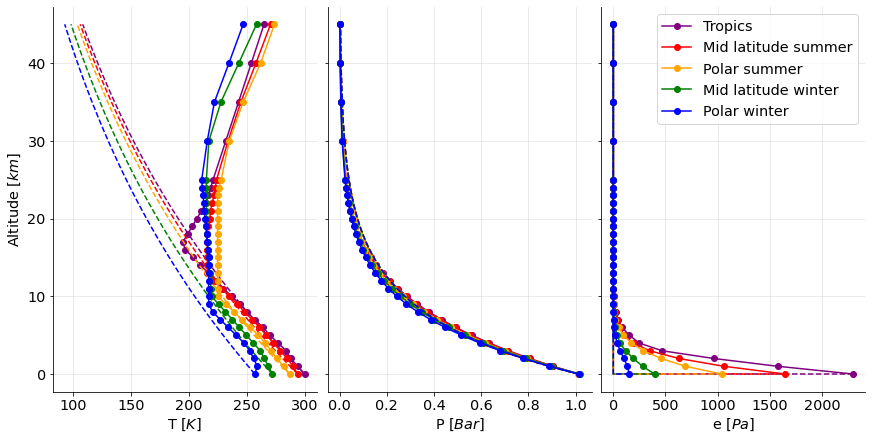

In [112]:
fig, axs  = plt.subplots(ncols = 3, nrows = 1, sharey = True, figsize = (12,6), layout = 'constrained')

z = np.linspace(0,45000,15000)

for atm in atms :
    
    if atm != 'EMPTATM' :
    
        prop_atm = Prop_atm(atm)

        z_profile = prop_atm.profiles(variable='z')
        T_profile = prop_atm.profiles(variable='T')
        P_profile = prop_atm.profiles(variable='P')
        x_profile = prop_atm.profiles(variable='x')

        T0 = np.interp(0,z_profile,T_profile)
        P0 = np.interp(0,z_profile,P_profile)
        wvp0 = np.interp(0,z_profile,x_profile)*P0

        axs[0].plot(T_B(z=z, gamma = T0*2.26e-2*1e-3, T0 = T0),z*1e-3, color = dict_atm[atm][1], linestyle = 'dashed')
        axs[1].plot(1e-5*P_B(z=z,g = 0.13e-3*T0*8.314, R=8.314,T0=T0,P0=P0),z*1e-3, color = dict_atm[atm][1], linestyle = 'dashed')
        axs[2].plot(wvp(z=z, wvp0 = wvp0, gamma = -6.5*1e-3,T0=T0),z*1e-3, color = dict_atm[atm][1],\
                    linestyle = 'dashed')

        axs[0].plot(T_profile,z_profile*1e-3, color = dict_atm[atm][1], marker = "o")
        axs[1].plot(P_profile*1e-5,z_profile*1e-3, color = dict_atm[atm][1], marker = "o")
        axs[2].plot(x_profile*P_profile,z_profile*1e-3, color = dict_atm[atm][1], marker = "o", label = dict_atm[atm][0])
    
xlabels = ['T $[K]$', 'P $[Bar]$', 'e $[Pa]$']
for i,ax in enumerate(axs) :
    ax.spines[['right', 'top']].set_visible(False)
    ax.grid(True, alpha = 0.3)
    ax.set_xlabel(xlabels[i])

axs[0].set_ylabel('Altitude $[km]$')
axs[2].legend()

### Approximations

# Emission sources

In [53]:
def source_categorie(
        exp : str,
        ncam : str,
        atms = atms):
    emissivity_Brutsaert
    dtype = np.dtype([
        ("SMLSATM",     np.float64),
        ("SMLWATM",     np.float64),
        ("SPOSATM",     np.float64),
        ("SPOWATM",     np.float64),
        ("STROATM",     np.float64),
        ("EMPTATM",     np.float64),
        ("TUXUATM",     np.float64),
    ])
    
    taux_surf = np.zeros(ncam, dtype = dtype)
    
    for j,atm in enumerate(atms) :
        
        if os.path.isdir(exp+'/'+atm) :
            
            for i in tqdm(range(ncam)) :
                
                output = np.loadtxt(exp+'/'+atm+f'/{i+1}/{i+1}_50_15_15.txt')
                taux_surf[atm][i] = output[output[:,1]==0,0].shape[0]/11250
                
    return taux_surf

def plot_source_categorie(
    ax,
    taux_surf,
    atm_up):
    
    n_cam = taux_surf["EMPTATM"].size
    
    ax.fill_between(x = np.arange(n_cam),y1 = 100*taux_surf[atm_up],\
                    y2 = 100*np.ones(n_cam), color = 'skyblue', label = 'Atmosphere')
    ax.fill_between(x = np.arange(n_cam),y1=np.zeros(n_cam),\
                    y2 = 100*taux_surf["EMPTATM"], color = 'lightcoral', label = 'Surface')
    ax.fill_between(x = np.arange(n_cam), y1 = 100*taux_surf[atm_up], y2 = 100*taux_surf["EMPTATM"],\
     facecolor='none', edgecolor='deepskyblue', hatch='//', linewidth=2, label = 'Occulting atmosphere (MLS)')
    
    ax.set_xlim((0,99))
    ax.set_ylim((0,100))
    ax.set_ylabel("View Factor (%) $[]$")
    ax.legend()

    ax.spines[['right', 'top']].set_visible(False)

def plot_SVFS_diff(
    ax,
    taux_surf):
    
    n_cam = taux_surf["EMPTATM"].size
    
    for atm in atms :
        
        if atm != "EMPTATM":
    
            ax.plot(np.arange(n_cam), 100*(taux_surf["EMPTATM"]-taux_surf[atm]), color = dict_atm[atm][1], \
                    label = dict_atm[atm][4])
        
    ax.set_ylabel('$SVF_{atm} - SVF_{geom}$ (%) $[]$')
    ax.set_xlabel("Index pyrgeometre")
    ax.set_ylim((0,None))
    ax.spines[['right', 'top']].set_visible(False)
    ax.legend(loc = 'upper right',ncol=5)
    ax.grid(True, alpha = 0.3)
    ax.set_ylim((0,40))

In [25]:
taux_surf = source_categorie(
        exp = '/home/barroisl/Transect_MC_auto/Data/lavey_30_100_atms_T',
        ncam = 100)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:04<00:00, 24.00it/s]


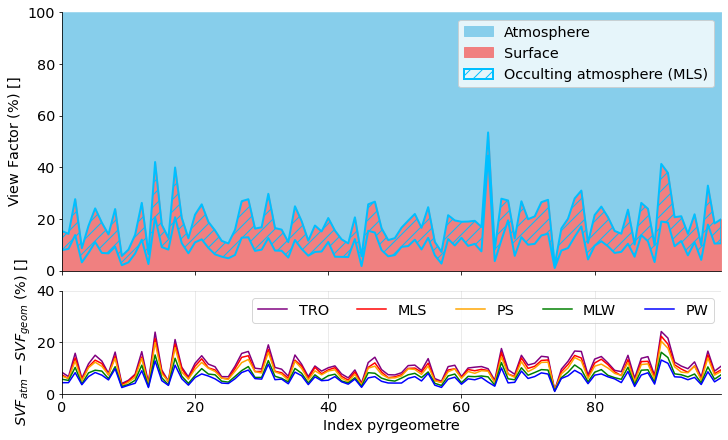

In [55]:
fig,axs = plt.subplots( nrows = 2, ncols = 1, figsize = (10,6), gridspec_kw={'height_ratios': [2.5,1]}, \
                       sharex=True,layout = 'constrained')

plot_source_categorie(
    ax = axs[0],
    taux_surf = taux_surf,
    atm_up = "SMLSATM")

plot_SVFS_diff(
    ax = axs[1],
    taux_surf = taux_surf)

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/source_emission.png")

# Sources flux distribution in z, lambda space

In [62]:
def plotting_z_lambda_space(
        ax,
        z : np.ndarray,
        step : int,
        surf : bool,
        loc,
        label,
        legend,
        color,
        exp = f"/home/barroisl/Transect_MC_auto/Data/lavey_30_100_atms_00_emis",
        dossier = '14',
        atm = "SMLWATM"):
    
    dz = z[1] - z[0]
    n_bins = z.size - 1
    
    im = None  # will hold the last mappable for the shared colorbar
    
    output = np.loadtxt(exp + f"/{atm}/{dossier}/{dossier}_50_15_15.txt")
    cam = np.loadtxt(exp + f"/{atm}/{dossier}/{dossier}_camera_tgt.txt")
    mc_set = MC_Set(output, cam[:3])

    ax.hlines(cam[2]/dz,0,30,linestyle = "dashed", color = 'k', label = 'Pyrgeometer altitude')

    prop_atm = Prop_atm(atm)
    if surf :
        tab = mc_set.tab_lambda_z_flux_surf(z=z, LW_int_edges=prop_atm.LW_int_edges)[:,::-1]
        cmap = "Reds"
    
    else :
        tab = mc_set.tab_lambda_z_flux(z=z, LW_int_edges=prop_atm.LW_int_edges)[:,::-1]
        cmap = "Blues"
    
    # largeur des colonnes :
    LW_ints = 10000/prop_atm.LW_int_edges
    mask_lbd_sup = LW_ints > 40
    mask_lbd_inf = LW_ints < 3
    LW_ints[mask_lbd_sup] = 40
    LW_ints[mask_lbd_inf] = 3
    
    largeurs = LW_ints[::-1,0] - LW_ints[::-1,1]
    x_edges = np.concatenate([[3], 3+np.cumsum(largeurs)])   # N+1 bords
    y_edges = np.arange(tab.shape[0] + 1)
    
    # Flux par interval spectral
    ax2 = ax.twinx()
    
    ax2.vlines(x_edges[0],0,np.sum(tab[:,0])/(x_edges[1]-x_edges[0]),color = color, label = 'Flux distribution')
    for j in range(len(x_edges[:-1])) :
        ax2.hlines(np.sum(tab[:,j])/(x_edges[j+1]-x_edges[j]),x_edges[j],x_edges[j+1],color = color)
        if j < 15 :
            ax2.vlines(x_edges[j+1],np.sum(tab[:,j])/(x_edges[j+1]-x_edges[j]),
                       np.sum(np.sum(tab[:,j+1])/(x_edges[j+2]-x_edges[j+1])),color = color)
    
    #ax2.set_ylim((0,0.4))
    ax2.set_ylabel('Flux spectral density $[W.m^{-2}.\mu m^{-1}]$')
    ax2.spines[['left', 'top']].set_visible(False)
    
    # Flux par altitude et interval spectral
    im = ax.pcolormesh(
        x_edges, y_edges,
        tab,
        norm=LogNorm(vmin=1e-3, vmax=1e1),
        cmap=cmap,
        shading='auto')
    
    im = ax.pcolormesh(
        x_edges, y_edges,
        tab,
        norm=LogNorm(vmin=1e-3, vmax=1e1),
        cmap=cmap,
        shading='auto')
    
    # --- Y ticks every 500 m ---
    step_bins = int(step / dz)  # number of bins per 500 m
    ytick_positions = np.arange(0, n_bins + 1, step_bins)
    ytick_labels = [f"{int(z[i])}" for i in ytick_positions]

    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(ytick_labels, fontsize=12)

    # --- X ticks: spectral 
    xtick_positions = np.arange(0,45,5)
    xtick_labels = [str(k) for k in xtick_positions]

    ax.set_xticks(xtick_positions)
    ax.set_xticklabels(xtick_labels, fontsize=12)
    
    ax.spines[['right', 'top']].set_visible(False)
    ax.grid(True, alpha = 0.3)
    ax.set_xlim((0,40))
    
    # --- Shared colorbar on the right, for the whole figure ---
    fig.colorbar(im, ax=ax, location=loc, label = label, )
    
def plotting_z_lambda_space_2(
        ax,
        ax_df,
        z : np.ndarray,
        step : int,
        surf : bool,
        loc,
        label,
        legend,
        color,
        exp = f"/home/barroisl/Transect_MC_auto/Data/lavey_30_100_atms_00_emis/",
        dossier = '14',
        atm = "SMLWATM"):
    
    dz = z[1] - z[0]
    n_bins = z.size - 1
    
    im = None  # will hold the last mappable for the shared colorbar
    
    output = np.loadtxt(exp + f"/{atm}/{dossier}/{dossier}_50_15_15.txt")
    cam = np.loadtxt(exp + f"/{atm}/{dossier}/{dossier}_camera_tgt.txt")
    mc_set = MC_Set(output, cam[:3])

    ax.hlines(cam[2]/dz,0,3,linestyle = "dashed", color = 'k', label = 'Pyrgeometer altitude')

    prop_atm = Prop_atm(atm)
    if surf :
        tab = mc_set.tab_lambda_z_flux_surf(z=z, LW_int_edges=prop_atm.LW_int_edges)[:,::-1]
        cmap = "Reds"
    
    else :
        tab = mc_set.tab_lambda_z_flux(z=z, LW_int_edges=prop_atm.LW_int_edges)[:,::-1]
        cmap = "Blues"
    
    # largeur des colonnes :
    LW_ints = 10000/prop_atm.LW_int_edges
    mask_lbd_sup = LW_ints > 40
    mask_lbd_inf = LW_ints < 3
    LW_ints[mask_lbd_sup] = 40
    LW_ints[mask_lbd_inf] = 3
    
    largeurs = LW_ints[::-1,0] - LW_ints[::-1,1]
    x_edges = np.concatenate([[3], 3+np.cumsum(largeurs)])   # N+1 bords
    y_edges = np.arange(tab.shape[0] + 1)
    
    # Flux par interval spectral
    
    if surf :
        label_ = 'Surface'
        frac = 0.64
        pad = 0.08
        aspect = 7
    else :
        label_ = 'Atmosphere'
        frac = 0.64
        pad = 0.08
        aspect = 20
    
    ax_df.vlines(x_edges[0],0,np.sum(tab[:,0])/(x_edges[1]-x_edges[0]),color = color, label = label_)
    for j in range(len(x_edges[:-1])) :
        ax_df.hlines(np.sum(tab[:,j])/(x_edges[j+1]-x_edges[j]),x_edges[j],x_edges[j+1],color = color)
        if j < 15 :
            ax_df.vlines(x_edges[j+1],np.sum(tab[:,j])/(x_edges[j+1]-x_edges[j]),
                       np.sum(np.sum(tab[:,j+1])/(x_edges[j+2]-x_edges[j+1])),color = color)
            
    # Passage en spectrale du tableau principal
    for j in range(tab.shape[1]):
        tab[:,j]=tab[:,j]/(x_edges[j+1]-x_edges[j])

    # Flux par altitude et interval spectral
    im = ax.pcolormesh(
        x_edges, y_edges,
        tab,
        norm=LogNorm(vmin=1e-3, vmax=1e1),
        cmap=cmap,
        shading='auto')
    """
    im = ax.pcolormesh(
        x_edges, y_edges,
        tab,
        norm=LogNorm(vmin=1e-3, vmax=1e1),
        cmap=cmap,
        shading='auto')
    """
    # --- Y ticks every step dz m ---
    step_bins = int(step / dz)
    ytick_positions = np.arange(0, n_bins + 1, step_bins)
    ytick_labels = [f"{int(z[i])}" for i in ytick_positions]

    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(ytick_labels, fontsize=12)

    # --- X ticks: spectral 
    xtick_positions = np.arange(0,45,5)
    xtick_labels = [str(k) for k in xtick_positions]

    ax.set_xticks(xtick_positions)
    ax.set_xticklabels(xtick_labels, fontsize=12)
    
    ax.spines[['right', 'top']].set_visible(False)
    ax_df.spines[['right', 'top']].set_visible(False)
    ax.grid(True, alpha = 0.3)
    ax.set_xlim((0,40))

    if legend:
        ax.legend()
    
    # Colorbar indépendante du plot
    cmap = cmap 
    norm=LogNorm(vmin=1e-3, vmax=1e1)
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])                     
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', norm=norm,
                        fraction=frac, pad=pad, aspect = aspect, location = 'right')   
    cbar.set_label(label) #'(1/N)$F_\lambda$ $[W.m^{-2}.\mu m^{-1}]$'

    
H = 6.62607015e-34   # Planck constant      [J·s]
C = 2.99792458e8     # Speed of light        [m/s]
KB = 1.380649e-23    # Boltzmann constant    [J/K]
sigma = 5.67e-8

@nb.njit(cache = True)
def Planck_law(
    wavelength: float | np.ndarray, 
    temperature: float) -> float | np.ndarray:
              
    return (2 * H * C**2 / wavelength**5) / (np.exp(H * C / (wavelength * KB * temperature)) - 1)  

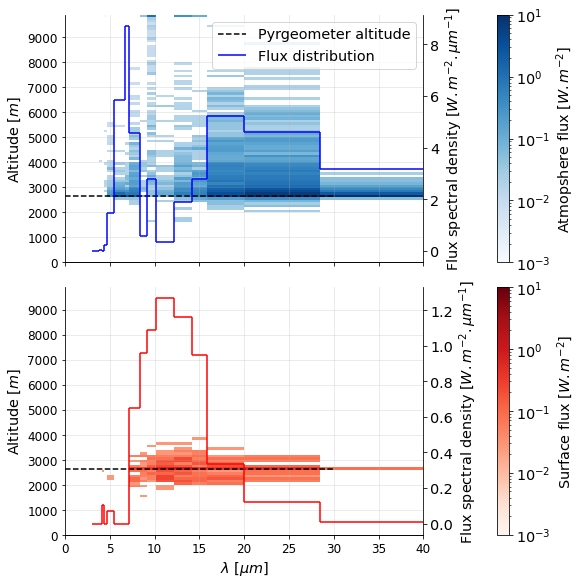

In [175]:
fig, axs = plt.subplots(nrows = 2, ncols = 1, sharex = True, figsize=(8, 8), layout='constrained')

z = np.arange(0, 10e3, 100)

plotting_z_lambda_space(
        ax = axs[0],
        z = z,
        step = 1000,
        surf = False,
        loc = 'right',
        legend = True,
        color = 'blue',
        label = 'Atmopshere flux $[W.m^{-2}]$')

handles, labels = [], []
for a in fig.axes:
    h, l = a.get_legend_handles_labels()
    handles += h
    labels += l
axs[0].legend(handles, labels)

plotting_z_lambda_space(
        ax = axs[1],
        z = z,
        step = 1000,
        surf = True,
        loc = 'right',
        legend = False,
        color = 'red',
        label = 'Surface flux $[W.m^{-2}]$')

for ax in axs :
    ax.set_ylabel('Altitude $[m]$')

axs[1].set_xlabel('$\lambda$ $[\mu m]$')

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/z_lambda_flux_distribution.png")

### Autre arangement

In [73]:
ds_ecrins = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/lavey_topo_params_30.nc")
ds_ecrins['ts'] = (['y','x'], altit_T(dem = ds_ecrins['zs'].values, 
                                        T0 = 273.15,
                                        z0 = 1300, 
                                        lapse_rate = 0.0))

topo_cam_tgt = np.loadtxt('/home/barroisl/Transect_MC_auto/camera_tgt/polygon_lavey_30_100.txt')[13]
print(ds_ecrins.ts.interp(x = topo_cam_tgt[0],y = topo_cam_tgt[1]).values)

prop_atm = Prop_atm('SMLSATM')

T = prop_atm.profiles(variable='T')
z = prop_atm.profiles(variable='z')

T_cam = np.interp(topo_cam_tgt[2],z,T)
print(T_cam)

273.15
281.184


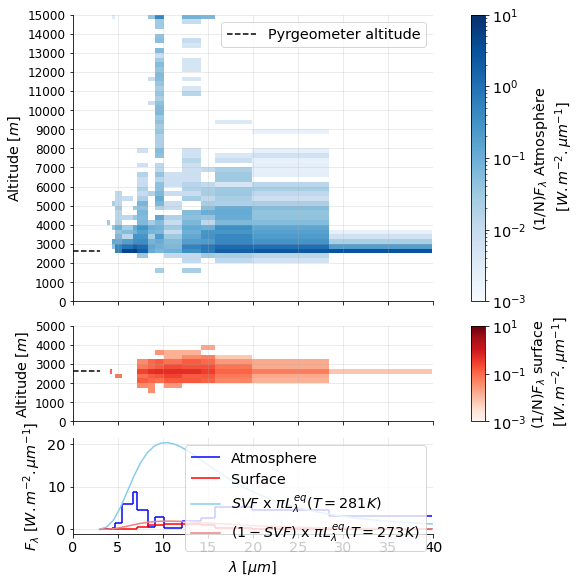

In [76]:
gs_kw = dict(width_ratios=[1], height_ratios=[3,1,1])
fig, axs = plt.subplot_mosaic([['upper'], ['center'],['lower']],
                              gridspec_kw=gs_kw, figsize=(8,8),
                              layout="constrained", sharex = True)

z_atm = np.arange(0, 15.25e3, 250)

plotting_z_lambda_space_2(
        ax = axs['upper'],
        ax_df = axs['lower'],
        z = z_atm,
        step = 1000,
        surf = False,
        loc = 'right',
        legend = True,
        color = 'blue',
        label = '(1/N)$F_{\lambda}$ Atmosphère \n $[W.m^{-2}.\mu m^{-1}]$')
"""
handles, labels = [], []
for a in fig.axes:
    h, l = a.get_legend_handles_labels()
    handles += h
    labels += l
axs['upper'].legend(handles, labels)
"""
z_surf = np.arange(0, 5.25e3, 250)

plotting_z_lambda_space_2(
        ax = axs['center'],
        ax_df = axs['lower'],
        z = z_surf,
        step = 1000,
        surf = True,
        loc = 'right',
        legend = False,
        color = 'red',
        label = '(1/N)$F_{\lambda}$ surface \n $[W.m^{-2}.\mu m^{-1}]$')



wl = np.linspace(3,40)
axs['lower'].plot(wl, 0.9*np.pi*1e-6*Planck_law(wavelength = wl*1e-6,temperature=281), \
           color = 'skyblue', label = '$SVF$ x $\pi L_{\lambda}^{eq}(T=281 K)$')

wl = np.linspace(3,40)
axs['lower'].plot(wl, 0.1*np.pi*1e-6*Planck_law(wavelength = wl*1e-6,temperature=273), \
           color = 'lightcoral', label = '$(1-SVF)$ x $\pi L_{\lambda}^{eq}(T=273 K)$')

axs['upper'].set_ylabel('Altitude $[m]$')
axs['center'].set_ylabel('Altitude $[m]$')
axs['lower'].set_ylabel('$F_{\lambda}$ $[W.m^{-2}.\mu m^{-1}]$')
axs['lower'].set_xlabel('$\lambda$ $[\mu m]$')
axs["lower"].grid(True, alpha = 0.3)
axs["lower"].legend(loc = 'upper right')

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/z_lambda_flux_distribution.png")

### Densité sur la verticale (Brutsaert approx)

In [197]:
def plot_F_z(
    ax,
    tab,
    z,
    color,
    label,
    linestyle,
    legend):
    
    dz = z[1]-z[0]
    
    y_edges = np.arange(tab.shape[0] + 1)*dz
    
    if legend:
        ax.hlines(y_edges[0],0,np.sum(tab[0,:])/(y_edges[1]-y_edges[0]),color = color, label = label, linestyle = linestyle)
    else :
        ax.hlines(y_edges[0],0,np.sum(tab[0,:])/(y_edges[1]-y_edges[0]),color = color, linestyle = linestyle)
    
    for i in range(len(y_edges[:-1])) :
        ax.vlines(np.sum(tab[i,:])/(y_edges[i+1]-y_edges[i]),y_edges[i],y_edges[i+1],color = color, linestyle = linestyle)
        if i < y_edges.size-2 :
            ax.hlines(y_edges[i+1],np.sum(tab[i,:])/(y_edges[i+1]-y_edges[i]),
                       np.sum(np.sum(tab[i+1,:])/(y_edges[i+2]-y_edges[i+1])),color = color, linestyle = linestyle)

def tab_z_flux_Brutsaert(output : np.ndarray,z,atm,LW_int_edges):

    res = np.zeros((z.size-1,LW_int_edges.shape[0])) # on prend en compte aussi les rayon arrivant en dessous de la caméra
    dz = z[1]-z[0]

    T_ref =275
    prop_atm = Prop_atm(atm)
    T_profile = prop_atm.profiles(variable = 'T')
    z_profile = prop_atm.profiles(variable = 'z')
    
    for i in range(output.shape[0]) :
        index_z = int(output[i,5]//dz)
        if index_z >= (z.size-1) :
            index_z = int(len(res)-1)

        T = np.interp(output[i,5],z_profile,T_profile)
        wl = output[i,-1]*1e-3
        F_CN = sigma*T_ref**4*1e-6*Planck_law(wavelength = wl*1e-6, temperature = T)/\
                (1e-6*Planck_law(wavelength = wl*1e-6, temperature = T_ref))
        
        mask = (10000/(LW_int_edges[:, 1]) <= wl*1e3/1000) & \
                (wl*1e3/1000 <= 10000/(LW_int_edges[:, 0]))
        index_lambda = np.where(mask)[0]
        
        res[index_z,index_lambda] += F_CN/11250

    return res                   

100%|█████████████████████████████████████████████| 6/6 [00:36<00:00,  6.16s/it]


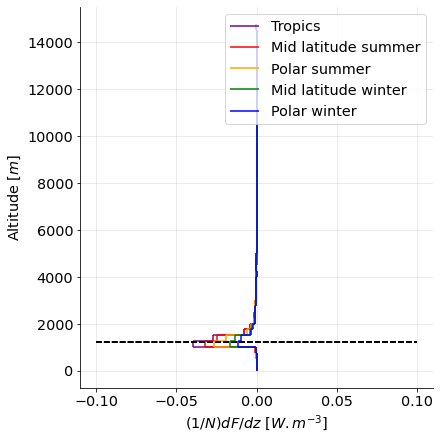

In [202]:
fig, ax = plt.subplots(figsize = (6,6), layout = 'constrained')

### Ce qui serait dans une fonction
z = np.arange(0,15e3,250)
dz = z[1]-z[0]
n_bins = z.size - 1
step = 1000

exp = f"/home/barroisl/Transect_MC_auto/Data/guiers_250_144_atms/"
dossier = '14'


####################################################

for atm in tqdm(atms) :
    
    if atm != "EMPTATM" and os.path.isdir(exp + f"{atm}/"):
        
        output = np.loadtxt(exp + f"{atm}/{dossier}/{dossier}_50_15_15.txt")
        cam = np.loadtxt(exp + f"/{atm}/{dossier}/{dossier}_camera_tgt.txt")
        mc_set = MC_Set(output, cam[:3])
        
        ax.hlines(cam[2],-0.05,0.05,linestyle = "dashed", color = 'k')
        
        prop_atm = Prop_atm(atm)
        
        ### htrdr
        tab_atm = mc_set.tab_lambda_z_flux(z=z, LW_int_edges=prop_atm.LW_int_edges)[:,::-1]
        """
        plot_F_z(
            ax=ax,
            tab=tab_atm,
            z=z,
            color = dict_atm[atm][1],
            label = dict_atm[atm][0],
            linestyle = 'solid',
            legend =True)
        """
        
        ### Brutsaert 
        tab_atm_B = tab_z_flux_Brutsaert(output=output[output[:,1]==1],z=z,atm=atm,LW_int_edges=prop_atm.LW_int_edges)[:,::-1]
        """
        plot_F_z(
            ax=ax,
            tab=tab_atm_B,
            z=z,
            color = dict_atm[atm][1],
            label = dict_atm[atm][0],
            linestyle = 'dashed',
            legend =False)
        """ 
        
        plot_F_z(
            ax=ax,
            tab=tab_atm-tab_atm_B,
            z=z,
            color = dict_atm[atm][1],
            label = dict_atm[atm][0],
            linestyle = 'solid',
            legend = True)
        
        
        """
        if atm == 'SMLSATM':
            tab_surf = mc_set.tab_lambda_z_flux_surf(z=z, LW_int_edges=prop_atm.LW_int_edges)[:,::-1]
            plot_F_z(
                ax=ax,
                tab=tab_surf,
                z=z,
                color = 'red',
                label = 'MLS')
        """

ax.grid(True, alpha = 0.3)
ax.spines[['right', 'top']].set_visible(False)
ax.set_ylabel('Altitude $[m]$')
ax.set_xlabel('$(1/N)dF_{htrdr-B}/dz$ $[W.m^{-3}]$')
ax.legend()

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/Brutsaert_htrdr.png")

# Symbolique sur l'approximation surface

In [148]:
def p_lambda_lambda(lambda_,T):
    
    return Planck_law(wavelength = lambda_, temperature = 275)/(np.sum(Planck_law(wavelength = np.linspace(0.001,1000000,1000000)*1e-6, temperature = 275)))

def error_grey_selective_approx(
        ax,
        dossier,
        legend,
        linestyle,
        atms = ["EMPTATM","SMLSAT","SMLWATM"]):

    path_dir = "/home/barroisl/Transect_MC_auto/Data/guiers_250_144_atms/"

    T_obs = np.linspace(245,305,10)
    
    for i,atm in enumerate(atms):
        
            bins = np.linspace(4,40,100)

            output = np.loadtxt(path_dir + atm +f'/{dossier}/{dossier}_50_15_15.txt')
            pos_camera = np.loadtxt(path_dir + atm +f'/{dossier}/{dossier}_camera_tgt.txt')[:3]
            
            SurfVF = output[output[:,1]==0,1].shape[0]/11250

            lambdas_surf = output[output[:,1]==0,-1]
            flux_CN_surf = np.array([SurfVF*sigma*t**4 for t in T_obs])
            flux_surf_symb = np.array([(1/11250)*np.sum(1e-6*(Planck_law(wavelength = lambdas_surf, temperature = t)*np.pi)/p_lambda_lambda(lambda_=lambdas_surf,T=275)) for t in T_obs])
            ax.plot(T_obs,flux_CN_surf-flux_surf_symb,color=dict_atm[atm][1], label = dict_atm[atm][0], linestyle = linestyle)
                
    ax.set_ylabel('FLux error $[W.m^{-2}]$')
    ax.set_xlabel('$T_{surf}$ $[K]$')
    ax.spines[['right', 'top']].set_visible(False)
    ax.grid(True, alpha = 0.3)
    ax.set_xlim((245,305))
    
    if legend :
        ax.legend()

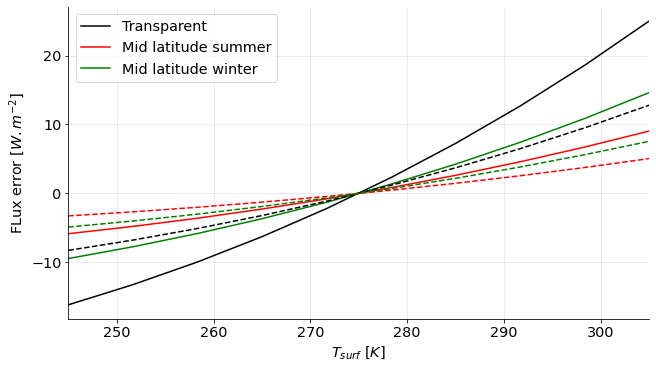

In [149]:
fig, ax = plt.subplots(figsize = (9,5), layout = 'constrained')

# SVF bas ~ 0.81
error_grey_selective_approx(
        ax = ax,
        dossier = '11',
        atms = ["EMPTATM","SMLSATM","SMLWATM"],
        linestyle = 'solid',
        legend = True)

# SVF haut ~ 0.91
error_grey_selective_approx(
        ax = ax,
        dossier = '91',
        atms = ["EMPTATM","SMLSATM","SMLWATM"],
        linestyle = 'dashed',
        legend = False)

"""
# SVF intermédiaire ~ 0.84
error_grey_selective_approx(
        ax = ax,
        dossier = '23',
        atms = ["EMPTATM","SMLSATM","SMLWATM"],
        linestyle = 'dashed',
        legend = False)
"""

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/grey_approximation_error.png")

# Scatter plot sur l'approximation T_caméra ou T_surface

In [4]:
def compute_CN_approx(atm):
    
    dtype = np.dtype([
        ("Flux",     np.float64),
        ("Flux_lambda_Cam",     np.float64),
        ("Flux_CN",     np.float64),
        ("Flux_CN_Cam",     np.float64)])
    
    A = np.zeros(100, dtype = dtype)
    
    Nbre_photon = 11250
    
    for ncam in tqdm(range(1,101)):
        
        output = np.loadtxt(dire + f"/{atm}/{ncam}/{ncam}_50_15_15.txt")
        pos_camera = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/polygon_chartreuse_250_100.txt")[ncam-1,:3]
        
        Tcam = ds_chartreuse.interp(x = pos_camera[0], y = pos_camera[1]).ts.values
        
        A["Flux"][ncam-1] = np.sum(output[output[:,1]==0,-2])/Nbre_photon
        
        T_ref = 275
        lambdas_surf = output[output[:,1]==0,-1]*1e-3
        A["Flux_lambda_Cam"][ncam-1] = ((sigma*T_ref**4)/11250)*np.sum(1e-6*Planck_law(wavelength=lambdas_surf*1e-6,temperature=Tcam)/\
                           (1e-6*Planck_law(wavelength=lambdas_surf*1e-6,temperature=T_ref)))
        
        x_pts = xr.DataArray(output[output[:,1]==0,3], dims="points")
        y_pts = xr.DataArray(output[output[:,1]==0,4], dims="points")
        LW_CN = 0.98*sigma*ds_chartreuse.interp(x=x_pts,y=y_pts).ts.values**4
        A["Flux_CN"][ncam-1] = np.sum(LW_CN)/Nbre_photon
        
        A["Flux_CN_Cam"][ncam-1] = (LW_CN.size/Nbre_photon)*0.98*sigma*Tcam**4
        
    return A

In [5]:
ds_chartreuse = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/chartreuse_thomas_topo_params.nc")
dire = "/home/barroisl/Transect_MC_auto/Data/chartreuse_250_100_atms"
atms = ["SMLSATM","SMLWATM","EMPTATM"]

A_SMLSATM = compute_CN_approx("SMLSATM")
A_SMLWATM = compute_CN_approx("SMLWATM")
A_STROATM = compute_CN_approx("STROATM")
A_EMPTATM = compute_CN_approx("EMPTATM")

100%|█████████████████████████████████████████| 100/100 [00:14<00:00,  7.04it/s]


In [6]:
def plot_scatter(ax, A, color, legend):
    
    RMSE_etoile = np.sqrt(np.nanmean((A["Flux_lambda_Cam"]-A["Flux"])**2))
    RMSE_disque = np.sqrt(np.nanmean((A["Flux_CN"]-A["Flux"])**2))
    RMSE_diamond = np.sqrt(np.nanmean((A["Flux_CN_Cam"]-A["Flux"])**2))
    
    if legend :
        # Flux lambda_Cam vs Flux
        ax.scatter(A["Flux"],A["Flux_lambda_Cam"], marker = '*',color = color, alpha = 0.5,\
                   label = "$(1/N)\sum_{i} L_\lambda^{eq}(T_{pyr})/p_\Lambda(\lambda_i)$" + f" ; RMSE = {RMSE_etoile:.2e}"+ " $W.m^{-2}$")

        # Flux CN vs Flux
        ax.scatter(A["Flux"],A["Flux_CN_Cam"], marker = 'd',color = color, alpha = 0.5,\
                   label = "$(1-SVF)\epsilon\sigma T_{pyr}^4$" + f" ; RMSE = {RMSE_diamond:.2e}"+ " $W.m^{-2}$")
        # Flux CN_Cam vs Flux
        ax.scatter(A["Flux"],A["Flux_CN"], color = color, \
                   label = "$(1/N)\sum_{i}\epsilon\sigma T_{i,surf}^4$" + f" ; RMSE = {RMSE_disque:.2e}" + " $W.m^{-2}$", edgecolor = 'k')

    else :
        # Flux lambda_Cam vs Flux
        ax.scatter(A["Flux"],A["Flux_lambda_Cam"], marker = '*',color = color, alpha = 0.5,\
                   label = f"RMSE = {RMSE_etoile:.2e}"+ " $W.m^{-2}$")

        # Flux CN_Cam vs Flux
        ax.scatter(A["Flux"],A["Flux_CN"], color = color, \
                   label = f"RMSE = {RMSE_disque:.2e}" + " $W.m^{-2}$", edgecolor = 'k')
        
        # Flux CN vs Flux
        ax.scatter(A["Flux"],A["Flux_CN_Cam"], marker = 'd',color = color, alpha = 0.5,\
                   label = f"RMSE = {RMSE_diamond:.2e}"+ " $W.m^{-2}$")
        
    ax.plot([0,60],[0,60], c = 'k', linestyle = 'dashed')

    ax.spines[['right', 'top']].set_visible(False)
    ax.grid(True, alpha = 0.3)
    ax.set_aspect('equal')
    ax.legend(loc = 'upper center')
    
def plot_residus(
    ax,
    A,
    topo_cam_tgt,
    color):
    
    ax.scatter(topo_cam_tgt[:,0], A["Flux"]-A["Flux_CN_Cam"], color = color)
    
    ax.grid(True, alpha = 0.3)
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_xlabel('$SVF$ $[]$')
    ax.set_ylabel('$F_{s, model} - F_{s, htrdr}$ $[W.m^{-2}]$')

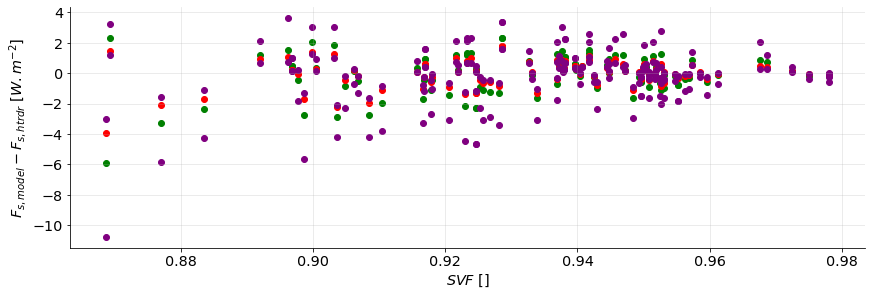

In [7]:
topo_cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_chartreuse_250_100.txt")

fig, ax = plt.subplots(figsize = (12,4), layout = 'constrained')

plot_residus(
    ax = ax,
    A = A_SMLWATM,
    topo_cam_tgt = topo_cam_tgt,
    color = dict_atm["SMLWATM"][1])

plot_residus(
    ax = ax,
    A = A_SMLSATM,
    topo_cam_tgt = topo_cam_tgt,
    color = dict_atm["SMLSATM"][1])
    
plot_residus(
    ax = ax,
    A = A_EMPTATM,
    topo_cam_tgt = topo_cam_tgt,
    color = dict_atm["STROATM"][1])

plot_residus(
    ax = ax,
    A = A_STROATM,
    topo_cam_tgt = topo_cam_tgt,
    color = dict_atm["STROATM"][1])

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/residus_svf.png")

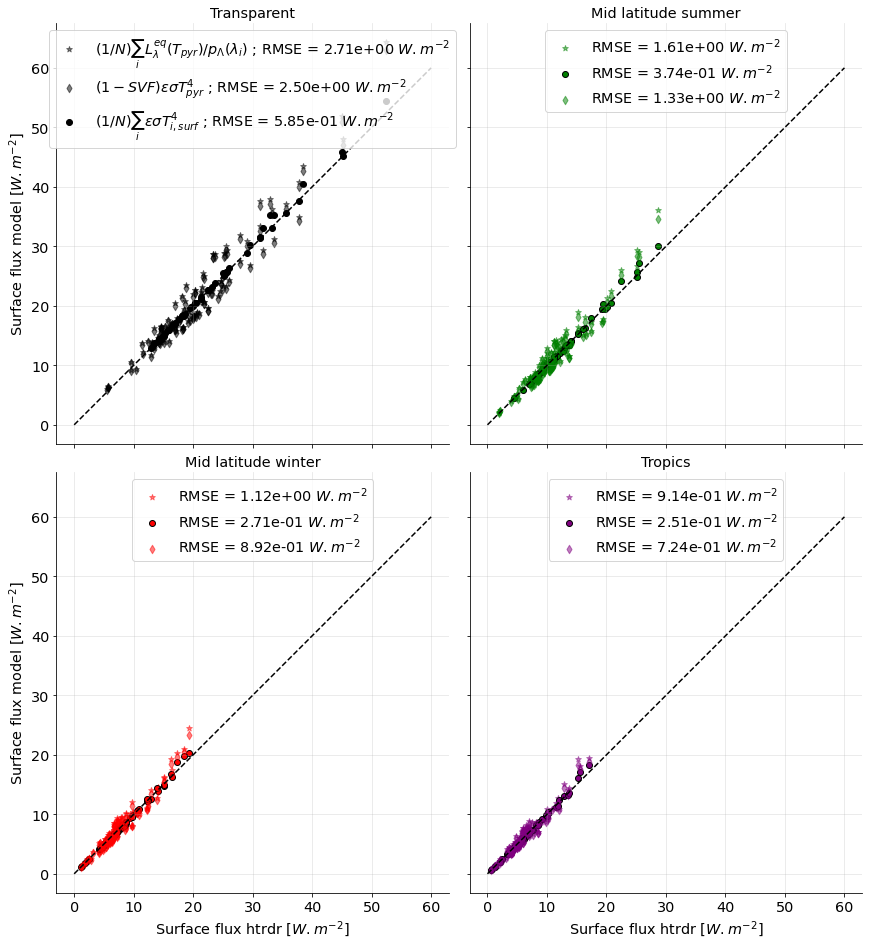

In [8]:
fig, axs = plt.subplots(nrows = 2, ncols = 2, sharex = True, sharey = True, figsize = (12,13), layout = 'constrained')

plot_scatter(axs[0,0], A_EMPTATM, legend = True, color = dict_atm["EMPTATM"][1])
plot_scatter(axs[0,1], A_SMLWATM, legend = False,  color = dict_atm["SMLWATM"][1])
plot_scatter(axs[1,0], A_SMLSATM, legend = False,  color = dict_atm["SMLSATM"][1])
plot_scatter(axs[1,1], A_STROATM, legend = False,  color = dict_atm["STROATM"][1])

axs[0,0].set_title(dict_atm["EMPTATM"][0])
axs[0,1].set_title(dict_atm["SMLSATM"][0])
axs[1,0].set_title(dict_atm["SMLWATM"][0])
axs[1,1].set_title(dict_atm["STROATM"][0])

for i in range(2):
    for j in range(2):
        if i%2 == 1 :
            axs[i,j].set_xlabel('Surface flux htrdr $[W.m^{-2}]$')
        if j%2 == 0 :
            axs[i,j].set_ylabel('Surface flux model $[W.m^{-2}]$')

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/scatter_approx_CN_Cam.png")

# SVF par atmosphère

### Regression linéaire du SVF

In [14]:
def plotting_atms_SVF_and_flux_with_regression_2(
        ax):
    
    atms = ['SMLSATM','SMLWATM','SPOSATM','SPOWATM','STROATM']
    
    dict_atm = {"SMLSATM" : ["Mid latitude summer", "red", "Reds", cm.Reds, ],
            "SMLWATM" : ["Mid latitude winter", "green", "Greens", cm.Greens],
            "SPOSATM" : ["Polar summer", "orange","Oranges",cm.Oranges],
            "SPOWATM" : ["Polar winter", "blue","Blues",cm.Blues],
            "STROATM" : ["Tropics", "purple","Purples",cm.Purples],
            "EMPTATM" : ["Transparent", "black","Greys",cm.Greys],
            "TUXUATM" : ["Uniforme", "yellow","YlGn", cm.YlGn]}
    
    ########## Tout d'un coup ###########
    
    dire = '/home/barroisl/Transect_MC_auto/Output/'
    taux_surf = np.load(dire + "taux_surf_e_g.npy")
    taux_atm = np.load(dire + "taux_atm_e_g.npy")
    flux_surf = np.load(dire + "flux_surf_e_g.npy")
    flux_atm = np.load(dire + "flux_atm_e_g.npy")
    topo_params = np.load(dire + "topo_params_e_g.npy")    
    
    
    for i,atm in enumerate(atms):
                        
        X = topo_params[:,0].reshape(-1, 1)
        #X = (1-taux_surf[:,5]).reshape(-1, 1)
        Y = (1-taux_surf[:,i])
        lm = linear_model.LinearRegression()
        lm.fit(X, Y)  # fitting the model
        r2 = lm.score(X, Y)
        x = [min(X),max(X)]
        ax.plot(x, lm.coef_*x+lm.intercept_, linestyle = 'dashed', color = dict_atm[atm][1])

        ax.scatter(topo_params[:,0],(1-taux_surf[:,i]), marker = '*', s = 70, c = dict_atm[atm][1],\
               label = dict_atm[atm][0] + f' ; $R^2 ={round(r2,3)}$ ', alpha = 0.7) #topo_params[:,-1]

    ax.plot([0.5,1],[0.5,1], linestyle = 'solid',color = 'k', label = '$y=x$')
    
    #ax.legend()
    ax.set_xlim((0.55,1))
    ax.set_ylim((0.55,1))
    ax.set_aspect('equal')
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_xlabel('$SVF_{geom}$ $[]$')
    ax.set_ylabel('$SVF$ $[]$')
    ax.grid(True, alpha = 0.3)
    
def SVF_regression_and_water_vapor():

    atms = ['SMLSATM','SMLWATM','SPOSATM','SPOWATM','STROATM']

    dire = '/home/barroisl/Transect_MC_auto/Output/'
    taux_surf = np.load(dire + "taux_surf_e_g.npy")
    taux_atm = np.load(dire + "taux_atm_e_g.npy")
    flux_surf = np.load(dire + "flux_surf_e_g.npy")
    flux_atm = np.load(dire + "flux_atm_e_g.npy")
    topo_params = np.load(dire + "topo_params_e_g.npy")    
    
    dtype = np.dtype([
        ("SMLSATM",     np.float64),
        ("SMLWATM",     np.float64),
        ("SPOSATM",     np.float64),
        ("SPOWATM",     np.float64),
        ("STROATM",     np.float64)])
    
    coeffs = np.zeros(5,dtype)

    for i,atm in tqdm(enumerate(atms)):
        
        prop_atm = Prop_atm(atm)
        T_profile = prop_atm.profiles(variable = "T")
        z_profile = prop_atm.profiles(variable = "z") 
        x_profile = prop_atm.profiles(variable = "x")
        P_profile = prop_atm.profiles(variable = "P") 
        
        #X = (1-taux_surf[:,5]).reshape(-1, 1)
        X = topo_params[:,0].reshape(-1, 1)
        Y = (1-taux_surf[:,i])
        lm = linear_model.LinearRegression()
        lm.fit(X, Y)  # fitting the model
        coeffs[atm][0] = lm.coef_
        coeffs[atm][1] = lm.intercept_
        coeffs[atm][0] = lm.coef_
        coeffs[atm][1] = lm.intercept_
        coeffs[atm][2] = water_vapor_mass_colonne(
                                    P = P_profile,
                                    T = T_profile,
                                    x = x_profile)
        coeffs[atm][3] = water_vapor_mass_colonne(
                                    P = P_profile[z_profile>2000],
                                    T = T_profile[z_profile>2000],
                                    x = x_profile[z_profile>2000])
        coeffs[atm][4] = water_vapor_mass_colonne(
                                    P = P_profile[z_profile>4000],
                                    T = T_profile[z_profile>4000],
                                    x = x_profile[z_profile>4000])
        
    return coeffs

In [8]:
coeffs_SVF_W = SVF_regression_and_water_vapor()

#np.save("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", coeffs_SVF_W, allow_pickle = True)
#coeffs = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)
coeffs_SVF_W

5it [00:12,  2.46s/it]


array([( 0.45122637, 0.52424212,  0.46853856, 0.55114995,  0.41621125),
       ( 0.56730224, 0.48408893,  0.54610867, 0.4514544 ,  0.60473299),
       (31.0356766 , 9.08129197, 21.94467187, 4.4670715 , 43.58864576),
       ( 6.20220695, 2.09990377,  5.17801428, 1.19307078,  8.10732879),
       ( 1.99457677, 0.58977306,  1.47804664, 0.30574587,  2.62065115)],
      dtype=[('SMLSATM', '<f8'), ('SMLWATM', '<f8'), ('SPOSATM', '<f8'), ('SPOWATM', '<f8'), ('STROATM', '<f8')])

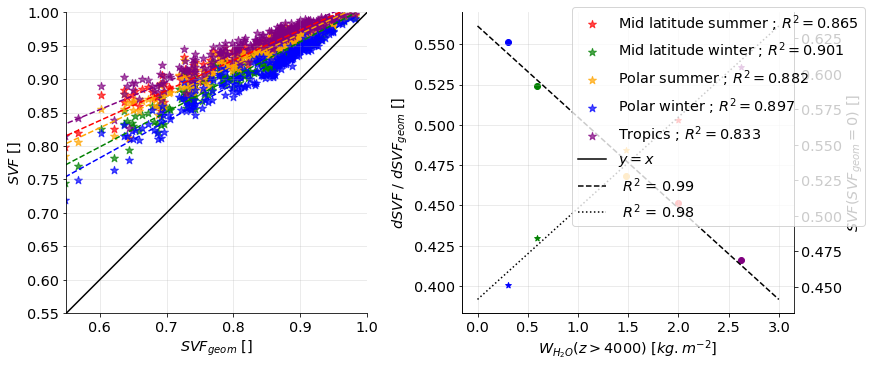

In [15]:
fig,axs = plt.subplots(nrows = 1, ncols = 2, figsize = (12,5), layout = 'constrained')

ax2 = axs[1].twinx()

plotting_atms_SVF_and_flux_with_regression_2(
        ax = axs[0])

plot_emissivity_coeff_cor_lin(
        ax = axs[1],
        coeffs = coeffs_SVF_W,
        index_W = 4,
        index_coeff = 0,
        marker = 'o',
        linestyle = 'dashed',
        legend = False)

plot_emissivity_coeff_cor_lin(
        ax = ax2,
        coeffs = coeffs_SVF_W,
        index_W = 4,
        index_coeff = 1,
        marker = '*',
        linestyle = 'dotted',
        legend = False)

axs[1].set_ylabel('$dSVF$ / $dSVF_{geom}$ $[]$')
ax2.set_ylabel('$SVF(SVF_{geom}=0)$ $[]$')

axs[1].spines[['right','top']].set_visible(False)
ax2.spines[['top']].set_visible(False)

axs[1].grid(True, alpha = 0.3)

fig.legend()

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/emissivity_coeff_reg_lin_SVF.png")

# Emissivity atmosphère

### Regression linéaire de l'emissivité de z, $\theta$

In [19]:
def emissivity_Brutsaert(
    T : np.ndarray | float,
    P : np.ndarray | float,
    x : np.ndarray | float):
    
    cste = 0.6684
    e = x*P
    return cste*((e/T)**(1/10))

def plot_emissivities(
    ax):
    
    flux_d = np.load("/home/barroisl/Transect_MC_auto/Data/z_profile_atms/flux_d.npy")
    
    emissivity_z_profile = np.load("/home/barroisl/Transect_MC_auto/Output/z_profiles_srfrad/emissivity_z_profile.npy",allow_pickle = True)

    for atm in atms :
        
        if os.path.isdir("/home/barroisl/Transect_MC_auto/Data/z_profile_atms/"+atm):

            prop_atm = Prop_atm(atm)
            T_profile = prop_atm.profiles(variable = "T")
            z_profile = prop_atm.profiles(variable = "z") 
            x_profile = prop_atm.profiles(variable = "x")
            P_profile = prop_atm.profiles(variable = "P") 

            z_to_plot = z_profile[z_profile <= 4000]
            T_to_plot = T_profile[z_profile <= 4000]
            x_to_plot = x_profile[z_profile <= 4000]
            P_to_plot = P_profile[z_profile <= 4000]
            
            emissivity_B_to_plot = emissivity_Brutsaert(T = T_to_plot,
                                                P = P_to_plot,
                                                x = x_to_plot)
            ax.plot(emissivity_B_to_plot,z_to_plot, marker = '*',
                               color = dict_atm[atm][1])

            flux_d_atm = np.interp(z_to_plot, flux_d["z"][1:], flux_d[atm][1:])

            ax.plot(flux_d_atm/(sigma*T_to_plot**4),z_to_plot, marker = 'o',
                   color = dict_atm[atm][1])

            X = z_to_plot.reshape(-1,1)
            Y = flux_d_atm/(sigma*T_to_plot**4)
            lm = linear_model.LinearRegression()
            lm.fit(X, Y)  # fitting the model
            r2 = lm.score(X, Y)
            x = np.linspace(0,4000,1000)
            ax.plot(lm.coef_*x+lm.intercept_,x , linestyle = 'dashed', color = dict_atm[atm][1],
                   label = dict_atm[atm][0] + ' ; $R^2$ = '+ f"{round(r2,2)}")        

    ax.set_ylim((0,4100))
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_xlabel('Emissivity $[]$')
    ax.set_ylabel('Altitude [$m$]')
    ax.legend()
    ax.grid(True, alpha = 0.3)

In [232]:
def npy_emissivity_rotative(z : float):
    
    angles = np.linspace(-np.pi/2, np.pi/2,10)

    atms = ["SPOSATM","SPOWATM","STROATM","SMLSATM","SMLWATM"]
    
    dtype = np.dtype([
        ("SMLSATM",     np.float64),
        ("SMLWATM",     np.float64),
        ("SPOSATM",     np.float64),
        ("SPOWATM",     np.float64),
        ("STROATM",     np.float64)])

    res = np.zeros((8,3), dtype)

    for atm in atms :
        
        prop_atm = Prop_atm(atm)
        z_profile = prop_atm.profiles(variable = "z")
        T_profile = prop_atm.profiles(variable = "T")
        sigma = 5.67e-8
        T = np.interp(z,z_profile,T_profile)
        CN_lum_e = sigma*(T**4)
        print(CN_lum_e)
        
        for i in tqdm(range(1,9)):
            mc_set = MC_Set(data_path = np.loadtxt(f'/home/barroisl/Transect_MC_auto/Data/rotated_cam_plain_{z}/{atm}/{i+1}/{i+1}_50_15_15.txt'),\
                            pos_camera = np.array([235000,5015000,z]))
            Atm_flux = mc_set.W_atm*mc_set.W_tot/mc_set.Nbre_photon
            Atm_flux_generalised = Atm_flux*(mc_set.Nbre_photon/(mc_set.Nbre_photon-mc_set.Nbre_surf))

            res[atm][i-1,0] = angles[i]
            res[atm][i-1,1] = Atm_flux/CN_lum_e
            res[atm][i-1,2] = Atm_flux_generalised/CN_lum_e
        
    return res

"""
z0 = 2000
res = npy_emissivity_rotative(z = z0)

np.save(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/rotated_emissivity_{z0}.npy",res)
"""

def calculating_R2(
    y,
    y_pred):
    
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    
    return 1 - ss_res / ss_tot
    

def plot_rotated_emissivity(
    ax,
    res,
    z0):
    
    for atm in atms :
        if atm != "TUXUATM" and atm != "EMPTATM":
            
            prop_atm = Prop_atm(atm)
            z_profile = prop_atm.profiles(variable = "z")
            T = np.interp(z0,z_profile,prop_atm.profiles(variable = "T"))
            x = np.interp(z0,z_profile,prop_atm.profiles(variable = "x"))
            P = np.interp(z0,z_profile,prop_atm.profiles(variable = "P"))
                        
            emissivity_B = emissivity_Brutsaert(
                                T = T,
                                P = P,
                                x = x)
        
            ax.plot(res[atm][:,0],np.full_like(res[atm][:,0],emissivity_B),marker = '*', color = dict_atm[atm][1])
            
            ax.plot(res[atm][:,0],res[atm][:,2],marker = 'o', color = dict_atm[atm][1])
                    
            coefficients = np.polyfit(res[atm][:,0],res[atm][:,2], 2)
            x_new = np.linspace(-np.pi/2,np.pi/2,100)
            y_new = np.polyval(coefficients, x_new)
            y_pred = np.polyval(coefficients, res[atm][:,0])
            
            r2 = calculating_R2(
                y = res[atm][:,2],
                y_pred = y_pred)
            
            ax.plot(x_new,y_new, linestyle = 'dashed',color = dict_atm[atm][1],\
                    label = dict_atm[atm][0]+ ' ; $R^2$ = '+ f"{round(r2,2)}") 

    ax.legend()
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_xlabel('Zenital angle $[rad]$')
    ax.set_ylabel('Emissivity $[]$')
    ax.grid(True, alpha = 0.3)

In [233]:
z0 = 1000
res = npy_emissivity_rotative(z = z0)

np.save(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/rotated_emissivity_{z0}.npy",res)

z0 = 2000
res = npy_emissivity_rotative(z = z0)

np.save(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/rotated_emissivity_{z0}.npy",res)

358.57457485919997


 38%|████████████████▉                            | 3/8 [00:02<00:04,  1.16it/s]/home/barroisl/edstar/Simus/scripts/Functions_lw_analysis.py:257: RuntimeWarning: invalid value encountered in scalar divide
  self.Nbre_moyen_reflexion_exc = self.Nbre_reflexion/data_path[data_path[:,2] != 0].shape[0]
100%|█████████████████████████████████████████████| 8/8 [00:06<00:00,  1.22it/s]


255.5363879990036


100%|█████████████████████████████████████████████| 8/8 [00:05<00:00,  1.37it/s]


423.61602484319997


100%|█████████████████████████████████████████████| 8/8 [00:05<00:00,  1.37it/s]


... (10 outputs left out)

374.07828543749997


100%|█████████████████████████████████████████████| 8/8 [00:05<00:00,  1.39it/s]


280.4640607687159


100%|█████████████████████████████████████████████| 8/8 [00:05<00:00,  1.39it/s]


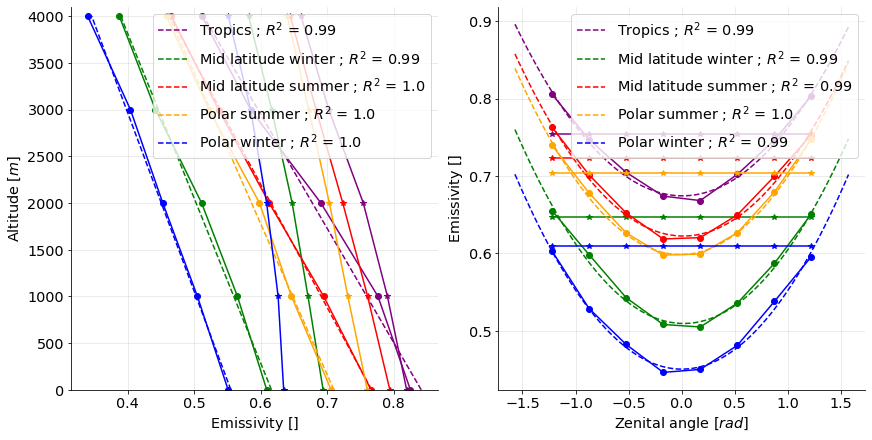

In [44]:
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (12,6), layout = 'constrained')

plot_emissivities(axs[0])

z0=2000
res = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/rotated_emissivity_{z0}.npy")

plot_rotated_emissivity(
    ax = axs[1],
    res = res,
    z0 = 2000)

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/emissivity_regression_2000.png")

### Regression linéaire des coefficients

In [7]:
def water_vapor_mass_colonne(
        P : np.ndarray,
        T : np.ndarray,
        x : np.ndarray,
        M = 18.015*1e-3,
        R = 8.314):
    
    return np.sum((x*P*M)/(R*T))*1000 # Adapté aux profiles ecRAD, 1 pt tout les 1000m verticaux

def coeffs_emissivities_z():
    
    flux_d = np.load("/home/barroisl/Transect_MC_auto/Data/z_profile_atms/flux_d.npy")

    atms = ["SPOSATM","SPOWATM","STROATM","SMLSATM","SMLWATM"]
    
    dtype = np.dtype([
        ("SMLSATM",     np.float64),
        ("SMLWATM",     np.float64),
        ("SPOSATM",     np.float64),
        ("SPOWATM",     np.float64),
        ("STROATM",     np.float64)])
    
    coeffs = np.zeros(5,dtype)

    for atm in atms :

        prop_atm = Prop_atm(atm)
        T_profile = prop_atm.profiles(variable = "T")
        z_profile = prop_atm.profiles(variable = "z") 
        x_profile = prop_atm.profiles(variable = "x") 
        P_profile = prop_atm.profiles(variable = "P") 

        z_to_plot = z_profile[z_profile <= 4000]
        T_to_plot = T_profile[z_profile <= 4000]
        
        flux_d_atm = np.interp(z_to_plot, flux_d["z"][1:], flux_d[atm][1:])

        X = z_to_plot.reshape(-1,1)
        Y = flux_d_atm/(sigma*T_to_plot**4)
        lm = linear_model.LinearRegression()
        lm.fit(X, Y)  # fitting the model
        
        coeffs[atm][0] = lm.coef_
        coeffs[atm][1] = lm.intercept_
        coeffs[atm][2] = water_vapor_mass_colonne(
                                    P = P_profile,
                                    T = T_profile,
                                    x = x_profile)
        coeffs[atm][3] = water_vapor_mass_colonne(
                                    P = P_profile[z_profile>2000],
                                    T = T_profile[z_profile>2000],
                                    x = x_profile[z_profile>2000])
        coeffs[atm][4] = water_vapor_mass_colonne(
                                    P = P_profile[z_profile>4000],
                                    T = T_profile[z_profile>4000],
                                    x = x_profile[z_profile>4000])
        
    np.save("/home/barroisl/Transect_MC_auto/Output/z_profiles/coeffs_emissivity_W_z.npy",coeffs,\
            allow_pickle = True)
        
    return coeffs

def coeffs_emissivities_theta(
            z0):
    
    
    res = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/rotated_emissivity_{z0}.npy")

    atms = ["SPOSATM","SPOWATM","STROATM","SMLSATM","SMLWATM"]
    
    dtype = np.dtype([
        ("SMLSATM",     np.float64),
        ("SMLWATM",     np.float64),
        ("SPOSATM",     np.float64),
        ("SPOWATM",     np.float64),
        ("STROATM",     np.float64)])
    
    coeffs = np.zeros(5,dtype)

    for atm in atms :
        
        prop_atm = Prop_atm(atm)
        T_profile = prop_atm.profiles(variable = "T")
        z_profile = prop_atm.profiles(variable = "z") 
        x_profile = prop_atm.profiles(variable = "x") 
        P_profile = prop_atm.profiles(variable = "P") 
        
        coeffs[atm][:2] = np.polyfit(res[atm][:,0],res[atm][:,2], 2)[:2]
        coeffs[atm][2] = water_vapor_mass_colonne(
                                    P = P_profile,
                                    T = T_profile,
                                    x = x_profile)
        coeffs[atm][3] = water_vapor_mass_colonne(
                                    P = P_profile[z_profile>2000],
                                    T = T_profile[z_profile>2000],
                                    x = x_profile[z_profile>2000])
        coeffs[atm][4] = water_vapor_mass_colonne(
                                    P = P_profile[z_profile>4000],
                                    T = T_profile[z_profile>4000],
                                    x = x_profile[z_profile>4000])
        
    np.save(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/coeffs_emissivity_W_theta_{z0}.npy",coeffs,\
            allow_pickle = True)
        
    return coeffs

#coeffs_z = coeffs_emissivities_z()
#coeffs_theta = coeffs_emissivities_theta(1000)

In [12]:
def plot_emissivity_coeff_cor_lin(
        ax,
        coeffs,
        index_W,
        index_coeff,
        marker,
        linestyle,
        legend):
    
    atms = ["SPOSATM","SPOWATM","STROATM","SMLSATM","SMLWATM"]

    for i, atm in enumerate(atms) :
        
        if legend :
            ax.scatter(coeffs[atm][index_W],coeffs[atm][index_coeff],c = dict_atm[atm][1], \
                       marker = marker, label = dict_atm[atm][0])
        else :
            ax.scatter(coeffs[atm][index_W],coeffs[atm][index_coeff],c = dict_atm[atm][1], \
                       marker = marker)           
        
        #axs[1].scatter(coeffs[atm][index_W],coeffs[atm][1],c = dict_atm[atm][1], marker = '*',label = dict_atm[atm][0])

    X = np.array([coeffs[atm][index_W] for atm in atms]).reshape(-1,1)
    Y = np.array([coeffs[atm][index_coeff] for atm in atms])
    lm = linear_model.LinearRegression()
    lm.fit(X, Y)  # fitting the model

    x = np.linspace(0,3,1000)
    ax.plot(x,lm.coef_[0]*x+ lm.intercept_, linestyle = linestyle, c = 'k',\
                    label = f" $R^2$ = "\
               + f"{round(lm.score(X, Y),2)}") #{lm.coef_[0]:.2e}"+"$x_{H_2O}$"+f"+ {lm.intercept_:.2e}" + " ;

    ax.set_xlabel('$W_{H_2O}(z>4000)$ $[kg.m^{-2}]$')

In [175]:
coeffs

array([(0.45122637, 0.52424212, 0.46853856, 0.55114995, 0.41621125),
       (0.56730224, 0.48408893, 0.54610867, 0.4514544 , 0.60473299),
       (0.01627166, 0.00388657, 0.01030155, 0.00151089, 0.02271397)],
      dtype=[('SMLSATM', '<f8'), ('SMLWATM', '<f8'), ('SPOSATM', '<f8'), ('SPOWATM', '<f8'), ('STROATM', '<f8')])

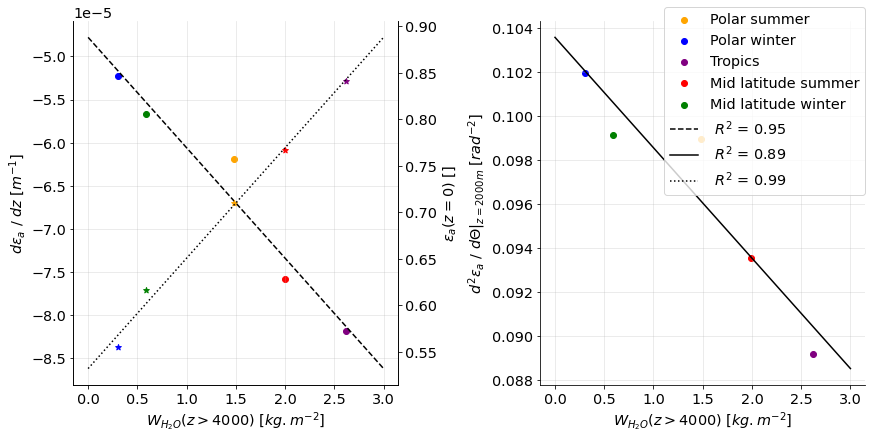

In [176]:
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (12,6), layout = 'constrained')

ax2 = axs[0].twinx()

plot_emissivity_coeff_cor_lin(
        ax = axs[0],
        coeffs = coeffs_z,
        index_W = 4,
        index_coeff = 0,
        marker = 'o',
        linestyle = 'dashed',
        legend = True)

plot_emissivity_coeff_cor_lin(
        ax = ax2,
        coeffs = coeffs_z,
        index_W = 4,
        index_coeff = 1,
        marker = '*',
        linestyle = 'dotted',
        legend = False)

plot_emissivity_coeff_cor_lin(
        ax = axs[1],
        coeffs = coeffs_theta,
        index_W = 4,
        index_coeff = 0,
        marker = 'o',
        linestyle = 'solid',
        legend = False)

fig.legend()

axs[1].set_ylabel('$d^2\epsilon_a$ / $d\Theta |_{z=2000m}$ $[rad^{-2}]$')
ax2.set_ylabel('$\epsilon_a(z=0)$ $[]$')
axs[0].set_ylabel('$d\epsilon_a$ / $dz$ $[m^{-1}]$')

axs[1].spines[['right','top']].set_visible(False)
axs[0].spines[['top']].set_visible(False)
ax2.spines[['top']].set_visible(False)

axs[0].grid(True, alpha = 0.3)
axs[1].grid(True, alpha = 0.3)

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/emissivity_coeff_reg_lin_theta.png")

# Espace des paramètres 

In [2]:
def plot_scatter(fig, ax,ds_topo,topo_cam_tgt, env, color_cam, color_env,s, add_legend,xlim, ylim):
    
    ax.scatter(ds_topo.svf.values.ravel(),ds_topo.zs.values.ravel(),s = s,\
               color = color_env, label = f'Env {env}', alpha = 0.5)
    ax.scatter(topo_cam_tgt[:,0],topo_cam_tgt[:,-1],s = s, color = color_cam,\
            label = f'Pyr {env}')
    
    if add_legend :
        ax.legend(loc='upper right')
        
    ax.set_xlim(xlim)
        
    ax.set_xlabel('$SVF_{geom}$ $[]$')
    ax.set_ylabel('Elevation $[m]$')
    ax.grid(True, alpha=0.3)
    ax.spines[['right', 'top']].set_visible(False)
    
def plot_kde(fig,axd,ds_topo,topo_cam_tgt,xlim,ylim, color_env, color_cam):
    
    values = ds_topo.svf.values[np.isfinite(ds_topo.svf.values)]
    counts, bins = np.histogram(values.ravel())
    axd['upper left'].hist(bins[:-1], bins, weights=counts, density = True,color = color_env, alpha = 0.5)
    
    counts, bins = np.histogram(topo_cam_tgt[:,0])
    axd['upper left'].hist(bins[:-1], bins, weights=counts, density = True,color = color_cam, alpha = 0.5)
    
    axd['upper left'].set_xlim(xlim)
    
    values = ds_topo.zs.values[np.isfinite(ds_topo.zs.values)]
    counts, bins = np.histogram(values.ravel())
    axd['lower_right'].hist(bins[:-1], bins, weights=counts, density = True,\
                            color = color_env, alpha = 0.5,orientation='horizontal')
    
    counts, bins = np.histogram(topo_cam_tgt[:,-1])
    axd['lower_right'].hist(bins[:-1], bins, weights=counts, density = True,\
                            color = color_cam, alpha = 0.5,orientation='horizontal')
    
    axd['lower_right'].set_ylim(ylim)

def plot_mosaic_2(fig, axd,ds_topo,topo_cam_tgt,color_cam, color_env,env,xlim,ylim):

    plot_scatter(fig = fig, ax = axd['lower left'],ds_topo = ds_topo,topo_cam_tgt = topo_cam_tgt,\
                 color_env = color_env, color_cam=color_cam, env = env,s = 10, add_legend = False,\
                 xlim = xlim, ylim = ylim)

    plot_kde(fig = fig, axd = axd,ds_topo = ds_topo,topo_cam_tgt = topo_cam_tgt,\
            color_env = color_env, color_cam = color_cam,xlim = xlim, ylim = ylim)

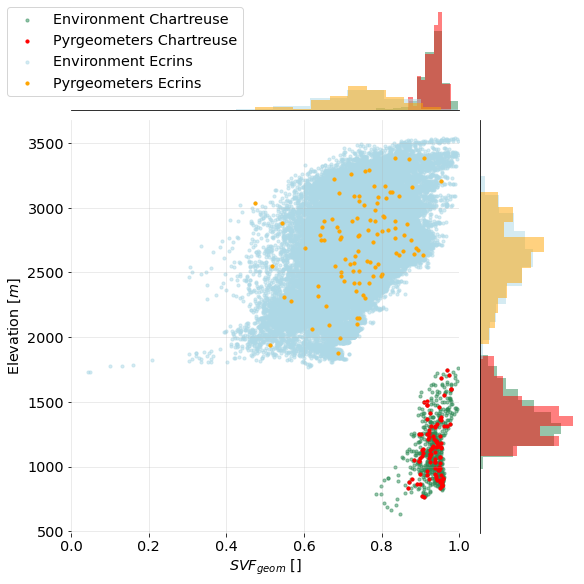

In [75]:
gs_kw = dict(width_ratios=[4,1], height_ratios=[1,4])
fig, axd = plt.subplot_mosaic([['upper left', 'upper_right'],
                               ['lower left', 'lower_right']],
                              gridspec_kw=gs_kw, figsize=(8,8),
                              layout="constrained")
xlim = (0,1)
ylim = (0,4100)

### Chartreuse ###
topo_cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_chartreuse_250_100.txt")
cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/polygon_chartreuse_250_100.txt")

ds_topo = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/chartreuse_thomas_topo_params.nc")
ds_topo_subset = ds_topo.where((ds_topo.x >= min(cam_tgt[:,0])) & (ds_topo.x <= max(cam_tgt[:,0]))&
                               (ds_topo.y >= min(cam_tgt[:,1])) & (ds_topo.y <= max(cam_tgt[:,1])))

plot_mosaic_2(fig=fig, axd=axd,ds_topo=ds_topo_subset,topo_cam_tgt=topo_cam_tgt,color_cam= 'red',\
             color_env = "seagreen",env = 'Chartreuse', xlim = xlim, ylim = ylim)

### Ecrins ###
cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/polygon_lavey_30_100.txt")
topo_cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_lavey_30_100.txt")

ds_topo = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/lavey_topo_params_30_00.nc")
ds_topo_subset = ds_topo.where((ds_topo.x >= min(cam_tgt[:,0])) & (ds_topo.x <= max(cam_tgt[:,0]))&
                               (ds_topo.y >= min(cam_tgt[:,1])) & (ds_topo.y <= max(cam_tgt[:,1])))

plot_mosaic_2(fig=fig, axd=axd,ds_topo=ds_topo_subset,topo_cam_tgt=topo_cam_tgt,color_cam= 'orange',\
             color_env = "lightblue",env = 'Ecrins', xlim = xlim, ylim = ylim)


### Axes ###
axd['upper_right'].spines[['left','right', 'top', 'bottom']].set_visible(False)
axd['upper_right'].set_xticks([])
axd['upper_right'].set_yticks([])

axd['lower_right'].spines[['bottom','right', 'top']].set_visible(False)
axd['lower_right'].set_xticks([])
axd['lower_right'].set_yticks([])

axd['upper left'].spines[['right', 'top', 'left']].set_visible(False)
axd['upper left'].set_xticks([])
axd['upper left'].set_yticks([])

fig.legend(loc = 'upper left')

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/espace_parametrique_C_E.png")

### Insertion dans un figures à 2/3 panels

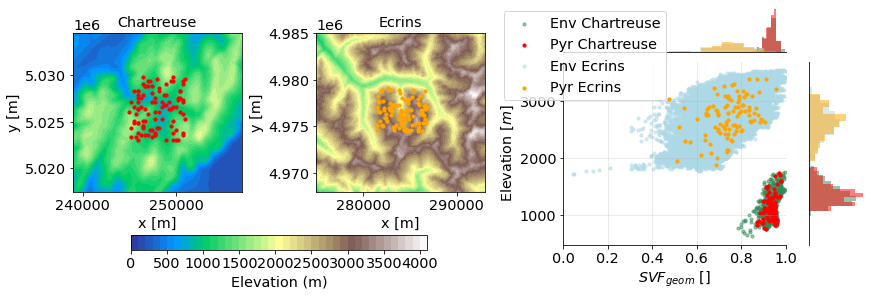

In [21]:
fig = plt.figure(figsize=(12, 4), layout="constrained")
gs_kw_ = dict(width_ratios=[1.3,1], height_ratios=[1])
outer = fig.subplot_mosaic([["left", "right"]],
                          gridspec_kw=gs_kw_)

# Remplace le panneau de droite par une sous figure
outer["right"].remove()
subfigd = fig.add_subfigure(outer["right"].get_subplotspec())

### Mosaic plot of parameter space
gs_kw = dict(width_ratios=[4,1], height_ratios=[1,4])
axd = subfigd.subplot_mosaic(
    [["upper left", "upper_right"],
     ["lower left", "lower_right"]],
    gridspec_kw=gs_kw
)

# Remplace le panneau de gauche par une sous figure
outer["left"].remove()
subfigg = fig.add_subfigure(outer["left"].get_subplotspec())

### Plot a deux scatter à gauche
gs_kw = dict(width_ratios=[4,1], height_ratios=[1,4])
axg = subfigg.subplot_mosaic([["left","right"]])

vmin = 0
vmax = 4100
xlim = (0,1)
ylim = (vmin,vmax)
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
levels = np.arange(vmin,vmax+100,100)
axg["left"].set_aspect('equal')
axg["right"].set_aspect('equal')

### Chartreuse ###
topo_cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_chartreuse_250_100.txt")
cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/polygon_chartreuse_250_100.txt")

ds_topo = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/chartreuse_thomas_topo_params.nc")
ds_topo_subset = ds_topo.where((ds_topo.x >= min(cam_tgt[:,0])) & (ds_topo.x <= max(cam_tgt[:,0]))&
                               (ds_topo.y >= min(cam_tgt[:,1])) & (ds_topo.y <= max(cam_tgt[:,1])))

plot_mosaic_2(fig=fig, axd=axd,ds_topo=ds_topo_subset,topo_cam_tgt=topo_cam_tgt,color_cam= 'red',\
             color_env = "seagreen",env = 'Chartreuse', xlim = xlim, ylim = ylim)

ds_topo.zs.plot.contourf(ax = axg["left"], cmap = 'terrain', levels = levels, norm=norm, add_colorbar=False)
axg["left"].scatter(cam_tgt[:,0],cam_tgt[:,1], marker = 'o', s = 10, color = 'red', label = 'Pyrgeometers')

axg["left"].set_xlim((239000,257000))
axg["left"].set_ylim((5017500,5034500))

axg["left"].set_title('Chartreuse')

### Ecrins ###
cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/polygon_lavey_30_100.txt")
topo_cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_lavey_30_100.txt")

ds_topo = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/lavey_topo_params_30_00.nc")
ds_topo_subset = ds_topo.where((ds_topo.x >= min(cam_tgt[:,0])) & (ds_topo.x <= max(cam_tgt[:,0]))&
                               (ds_topo.y >= min(cam_tgt[:,1])) & (ds_topo.y <= max(cam_tgt[:,1])))

plot_mosaic_2(fig=fig, axd=axd,ds_topo=ds_topo_subset,topo_cam_tgt=topo_cam_tgt,color_cam= 'orange',\
             color_env = "lightblue",env = 'Ecrins', xlim = xlim, ylim = ylim)

ds_topo.zs.plot.contourf(ax =  axg["right"], cmap = 'terrain', levels = levels, norm=norm, add_colorbar=False)
axg["right"].scatter(cam_tgt[:,0],cam_tgt[:,1], marker = 'o', s = 10, color = 'orange', label = 'Pyrgeometers')

axg["right"].set_xlim((275000,293000))
axg["right"].set_ylim((4968000,4985000))

axg["right"].set_title('Ecrins')

### Axes ###
axd['upper_right'].spines[['left','right', 'top', 'bottom']].set_visible(False)
axd['upper_right'].set_xticks([])
axd['upper_right'].set_yticks([])

axd['lower_right'].spines[['bottom','right', 'top']].set_visible(False)
axd['lower_right'].set_xticks([])
axd['lower_right'].set_yticks([])

axd['upper left'].spines[['right', 'top', 'left']].set_visible(False)
axd['upper left'].set_xticks([])
axd['upper left'].set_yticks([])

subfigd.legend(loc= 'upper left')

# Colorbar indépendante du plot
cmap = cm.terrain   
bounds = np.arange(vmin,vmax+100, 100)
norm = norm
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])                     
cbar = fig.colorbar(sm, ax=[axg["left"],axg["right"]], orientation='horizontal', boundaries = bounds,
                    fraction=0.08, pad=0.02, location = 'bottom')   
cbar.set_label('Elevation (m)')

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/espace_parametrique_C_E.png")

# Resultats models 

In [16]:
def correlation_htrdr_model_surf(
        ax,
        alpha : float,
        ds_ecrins : xr.Dataset,
        ds_chartreuse : xr.Dataset,
        atm_ : str,
        epsilon_surf = 0.98,
        epsilon_atm = 1,
        sigma = 5.67e-8):
    
    ########## Ecrins ###########
    taux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/taux_surf_tapadito.npy", allow_pickle = True)
    taux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/taux_atm_tapadito.npy", allow_pickle = True)
    flux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/flux_atm_tapadito.npy", allow_pickle = True)
    flux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/flux_surf_tapadito.npy", allow_pickle = True)
    topo_params = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_lavey_30_100.txt")
    
    cam_tgt = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/polygon_lavey_30_100.txt")
    
    coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)

    for i,atm in enumerate(atms):
        
        if atm in atm_ :
            
            if atm == 'SMLSATM' :
                index = 1
            elif atm == 'SMLWATM' :
                index = 2
            
            ########## Surf flux #############
            
            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])

            LW_CN_self = epsilon_surf*sigma*interpolate(
                ds = ds_ecrins,
                points = cam_tgt[:,:2],
                var_name = "ts")**4

            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])

            ax.scatter(flux_surf[atm],0.98*taux_surf_i*LW_CN_self, marker = 'o', edgecolor = 'black',s = 50, alpha = alpha,\
                                 color = dict_atm[atm][1])  
            ax.scatter(flux_surf[atm],0.98*(1-topo_params[:,0])*LW_CN_self, marker = '*', \
                       s = 50, alpha = alpha,color = dict_atm[atm][1], label = dict_atm[atm][0] + ' Ecrins') 
            
    ########## Guiers ###########
    taux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/taux_surf.npy")
    taux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/taux_atm.npy")
    flux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/flux_atm.npy")
    flux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/flux_surf.npy")
    topo_params = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_guiers_250_144.txt")
    
    cam_tgt = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/polygon_guiers_250_144.txt")
    
    colors = ["firebrick","lightgreen"]
    for i,atm in enumerate(atms):
        
        if atm in atm_ :
            
            if atm == 'SMLSATM' :
                index = 0
            elif atm == 'SMLWATM' :
                index = 1
            
            ########## Surf flux #############
            
            LW_CN_self = epsilon_surf*sigma*interpolate(
                ds = ds_chartreuse,
                points = cam_tgt[:,:2],
                var_name = "ts")**4

            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])

            ax.scatter(flux_surf[:,index],0.98*taux_surf_i*LW_CN_self, marker = 'o', edgecolor = 'black',s = 50, alpha = alpha,\
                                 color = colors[index])  
            ax.scatter(flux_surf[:,index],0.98*(1-topo_params[:,0])*LW_CN_self, marker = '*', \
                       s = 50, alpha = alpha,color = colors[index], label = dict_atm[atm][0] + ' Chartreuse') 
            
    ax.plot([0,175],[0,175], linestyle = 'dashed', color = 'k', label = '$y=x$')
            
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_ylabel('$LW_{s}$ ($W.m^{-2}$)')
    #ax.legend()
    #ax.set_aspect('equal')
    ax.set_xlim((0,175))
    ax.set_ylim((0,175))
    
    ax.set_xlabel('$LW_{htrdr, surf}$ $[W.m^{-2}]$')
    #axs[1].set_ylabel('$LW_{model,atm}$ ($W.m^{-2}$)')
    ax.set_ylabel('$LW_{model}$ $[W.m^{-2}]$', fontsize = 15)
    ax.set_aspect('equal')
    
def correlation_htrdr_model_atm(
        ax,
        alpha : float,
        atm_ : str,
        epsilon_surf = 0.98,
        epsilon_atm = 1,
        sigma = 5.67e-8):

    #### Ecrins ####
    taux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/taux_surf.npy", allow_pickle = True)
    taux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/taux_atm.npy", allow_pickle = True)
    flux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/flux_atm.npy", allow_pickle = True)
    
    topo_params = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_lavey_30_100.txt")
    cam_tgt = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/polygon_lavey_30_100.txt")

    emissivities_coeff = np.load("/home/barroisl/Transect_MC_auto/Output/z_profiles/coeffs_emissivity_W_z.npy")
    coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)

    emissivity_slope_1000 = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/coeffs_emissivity_W_theta_1000.npy", allow_pickle = True)
    emissivity_slope_2000 = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/coeffs_emissivity_W_theta_2000.npy", allow_pickle = True)

    for i,atm in enumerate(atms):
        
        if atm in atm_ :
            
            if atm == 'SMLSATM' :
                index = 1
            elif atm == 'SMLWATM' :
                index = 2
            
            ########## Atm flux #############
            
            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])
            
            emissivities = emissivities_coeff[atm][0]*topo_params[:,-1]+emissivities_coeff[atm][1]
            emissivities_corr_slope = emissivities + topo_params[:,3]**2*emissivity_slope_2000[atm][0]+\
                        topo_params[:,3]*emissivity_slope_2000[atm][1]
                
            prop_atm = Prop_atm(atm)
            T_profile = prop_atm.profiles(variable = "T")
            z_profile = prop_atm.profiles(variable = "z")
            P_profile = prop_atm.profiles(variable = "P")
            x_profile = prop_atm.profiles(variable = "x")
            
            T = np.interp(topo_params[:,-1], z_profile, T_profile) #-6.5 # pour prendre la température un poil plus haut
            LW_CN = emissivities_corr_slope*sigma*(T**4)
            
            emissivity_B = np.interp(topo_params[:,-1],z_profile,emissivity_Brutsaert(
                                                T = T_profile,
                                                P = P_profile,
                                                x = x_profile))
            LW_B = emissivity_B*sigma*(T**4)
            
            ax.scatter(flux_atm[:,index],topo_params[:,0]*LW_B, marker = '*', s = 50, alpha = alpha,\
                                             color = dict_atm[atm][1]) 
            
            ax.scatter(flux_atm[:,index],(1-taux_surf_i)*LW_CN, marker = 'o', s = 50, alpha = alpha,\
                             color = dict_atm[atm][1], edgecolor = 'black',label = dict_atm[atm][0]+' Ecrins') 
            
    ########## Guiers ###########
    taux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/taux_surf.npy")
    taux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/taux_atm.npy")
    flux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/flux_atm.npy")
    flux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/flux_surf.npy")
    topo_params = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_guiers_250_144.txt")
    
    cam_tgt = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/polygon_guiers_250_144.txt")        
        
    colors = ["firebrick","lightgreen"]
    for i,atm in enumerate(atms):
        
        if atm in atm_ :
            
            if atm == 'SMLSATM' :
                index = 0
            elif atm == 'SMLWATM' :
                index = 1
            
            ########## Atm flux #############
            
            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])
            
            emissivities = emissivities_coeff[atm][0]*topo_params[:,-1]+emissivities_coeff[atm][1]
            
            emissivities_corr_slope = emissivities + topo_params[:,3]**2*emissivity_slope_1000[atm][0]+\
                        topo_params[:,3]*emissivity_slope_1000[atm][1]                

            prop_atm = Prop_atm(atm)
            T_profile = prop_atm.profiles(variable = "T")
            z_profile = prop_atm.profiles(variable = "z")
            x_profile = prop_atm.profiles(variable = "x")
            P_profile = prop_atm.profiles(variable = "P")
            
            T = np.interp(topo_params[:,-1], z_profile, T_profile) #-6.5 # pour prendre la température un poil plus haut
            LW_CN = emissivities_corr_slope*sigma*(T**4)
            
            emissivity_B = np.interp(topo_params[:,-1],z_profile,emissivity_Brutsaert(
                                                T = T_profile,
                                                P = P_profile,
                                                x = x_profile))
            LW_B = emissivity_B*sigma*(T**4)
            
            ax.scatter(flux_atm[:,index],topo_params[:,0]*LW_B, marker = '*', s = 50, alpha = alpha,\
                                             color = dict_atm[atm][1]) 

            ax.scatter(flux_atm[:,index],(1-taux_surf_i)*LW_CN, marker = 'o', s = 50, alpha = alpha,\
                             color = colors[index], edgecolor = 'black',label = dict_atm[atm][0]+' Chartreuse') 
            
    ax.plot([70,320],[70,320], linestyle = 'dashed', color = 'k', label = '$y=x$')
            
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_ylabel('$LW_{s}$ ($W.m^{-2}$)')
    #ax.legend()
    #ax.set_aspect('equal')
    ax.set_xlim((70,320))
    ax.set_ylim((70,320))
    
    ax.set_xlabel('$LW_{htrdr,atm}$ $[W.m^{-2}]$')
    #axs[1].set_ylabel('$LW_{model,atm}$ ($W.m^{-2}$)')
    ax.set_ylabel('$LW_{model}$ $[W.m^{-2}]$', fontsize = 15)
    ax.set_aspect('equal')
    
def tab_RMSE_model_total(
        emissivity_slope,
        taux_surf,
        taux_atm, 
        flux_atm,
        flux_surf,
        topo_params,
        cam_tgt,
        ds_topo : xr.Dataset,
        epsilon_surf = 0.98,
        epsilon_atm =1,
        sigma = 5.67e-8):
    
    emissivities_coeff = np.load("/home/barroisl/Transect_MC_auto/Output/z_profiles/coeffs_emissivity.npy")
    coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)
       
    emissivity_slope_1000 = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/coeffs_emissivity_W_theta_1000.npy", allow_pickle = True)
    emissivity_slope_2000 = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/coeffs_emissivity_W_theta_2000.npy", allow_pickle = True)
    
    ### Choix : 
    index = 1
    atm = "SMLSATM"

    ########## Atm flux #############

    coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)
    taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])

    emissivities = emissivities_coeff[atm][0]*topo_params[:,-1]+emissivities_coeff[atm][1]
    emissivities_corr_slope = emissivities + topo_params[:,3]**2*emissivity_slope[atm][0]+\
                    topo_params[:,3]*emissivity_slope[atm][1]

    prop_atm = Prop_atm(atm)
    T_profile = prop_atm.profiles(variable = "T")
    z_profile = prop_atm.profiles(variable = "z")     
    T = np.interp(topo_params[:,-1], z_profile, T_profile) #-6.5 # pour prendre la température un poil plus haut
    LW_CN = emissivities*epsilon_atm*sigma*T**4

    LW_CN_corr_slope = emissivities_corr_slope*epsilon_atm*sigma*T**4  

    ########## Surf flux #############

    LW_CN_self = epsilon_surf*sigma*interpolate(
        ds = ds_topo,
        points = cam_tgt[:,:2],
        var_name = "ts")**4
    
    taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])

    ### Total ####
    RMSE_tot_geom = np.sqrt(np.sum((0.98*(1-topo_params[:,0])*LW_CN_self+topo_params[:,0]*LW_CN - (flux_surf[:,index]+flux_atm[:,index]))**2)/cam_tgt.shape[0])
    print("RMSE_tot_geom : ",f'{RMSE_tot_geom:.5e}')
    
    sigma_tot_geom = np.std(0.98*(1-topo_params[:,0])*LW_CN_self+topo_params[:,0]*LW_CN - (flux_surf[:,index]+flux_atm[:,index]))
    print("sigma_tot_geom : ",f'{sigma_tot_geom:.5e}')

    RMSE_tot_htrdr = np.sqrt(np.sum((0.98*taux_surf_i*LW_CN_self+(1-taux_surf_i)*LW_CN - (flux_surf[:,index]+flux_atm[:,index]))**2)/cam_tgt.shape[0])
    print("RMSE_tot_htrdr : ",f'{RMSE_tot_htrdr:.5e}')
    
    sigma_tot_htrdr = np.std(0.98*taux_surf_i*LW_CN_self+(1-taux_surf_i)*LW_CN - (flux_surf[:,index]+flux_atm[:,index]))
    print("sigma_tot_htrdr : ",f'{sigma_tot_htrdr:.5e}')

    RMSE_tot_slope_corr = np.sqrt(np.sum((0.98*taux_surf_i*LW_CN_self+(1-taux_surf_i)*LW_CN_corr_slope - (flux_surf[:,index]+flux_atm[:,index]))**2)/cam_tgt.shape[0])
    print("RMSE_tot_slope_corr : ",f'{RMSE_tot_slope_corr:.5e}')
    
    sigma_tot_slope_corr = np.std(0.98*taux_surf_i*LW_CN_self+(1-taux_surf_i)*LW_CN_corr_slope - (flux_surf[:,index]+flux_atm[:,index]))
    print("sigma_tot_slope_corr : ",f'{sigma_tot_slope_corr:.5e}')

    ### Surface ###
    RMSE_surf_geom = np.sqrt(np.sum((0.98*(1-topo_params[:,0])*LW_CN_self - flux_surf[:,0])**2)/cam_tgt.shape[0])
    print("RMSE_surf_geom : ", RMSE_surf_geom)
    
    sigma_surf_geom = np.std(0.98*(1-topo_params[:,0])*LW_CN_self - flux_surf[:,0])
    print("sigma_surf_geom : ",f'{sigma_surf_geom:.2e}')

    RMSE_surf_htrdr = np.sqrt(np.sum((0.98*taux_surf_i*LW_CN_self - flux_surf[:,index])**2)/cam_tgt.shape[0])
    print("RMSE_surf_htrdr : ", f'{RMSE_surf_htrdr:.2e}')
    
    sigma_surf_htrdr = np.std(0.98*taux_surf_i*LW_CN_self - flux_surf[:,index])
    print("sigma_surf_htrdr : ",f'{sigma_surf_htrdr:.2e}')

    ### Atmosphère ###
    RMSE_atm_geom = np.sqrt(np.sum((topo_params[:,0]*LW_CN - flux_atm[:,index])**2)/cam_tgt.shape[0])
    print("RMSE_atm_geom : ", f'{RMSE_atm_geom:.2e}')

    sigma_atm_geom = np.std(topo_params[:,0]*LW_CN - flux_atm[:,index])
    print("sigma_atm_geom : ",f'{sigma_atm_geom:.2e}')
    
    RMSE_atm_htrdr = np.sqrt(np.sum(((1-taux_surf_i)*LW_CN - flux_atm[:,index])**2)/cam_tgt.shape[0])
    print("RMSE_atm_htrdr : ", RMSE_atm_htrdr)
    
    sigma_atm_htrdr = np.std((1-taux_surf_i)*LW_CN - flux_atm[:,index])
    print("sigma_atm_htrdr : ",f'{sigma_atm_htrdr:.2e}')

    RMSE_atm_slope_corr = np.sqrt(np.sum(((1-taux_surf_i)*LW_CN_corr_slope - flux_atm[:,index])**2)/cam_tgt.shape[0])
    print("RMSE_atm_slope_corr : ", RMSE_atm_slope_corr)
    
    sigma_atm_slope_corr = np.std((1-taux_surf_i)*LW_CN_corr_slope - flux_atm[:,index])
    print("sigma_atm_slope_corr : ",f'{sigma_atm_slope_corr:.2e}')

def correlation_htrdr_model_total(
        ax,
        alpha : float,
        ds_chartreuse : xr.Dataset,
        ds_ecrins : xr.Dataset,
        atm_ : str,
        epsilon_surf = 0.98,
        epsilon_atm =1,
        sigma = 5.67e-8):
    
    emissivity_slope_1000 = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/coeffs_emissivity_W_theta_1000.npy", allow_pickle = True)
    emissivity_slope_2000 = np.load(f"/home/barroisl/Transect_MC_auto/Output/rotated_cam/coeffs_emissivity_W_theta_2000.npy", allow_pickle = True)
    
    #### Ecrins ####
    taux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/taux_surf.npy", allow_pickle = True)
    taux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/taux_atm.npy", allow_pickle = True)
    flux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/flux_atm.npy", allow_pickle = True)
    flux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00_emis/flux_surf.npy", allow_pickle = True)

    topo_params = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_lavey_30_100.txt")
    cam_tgt = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/polygon_lavey_30_100.txt")
    
    emissivities_coeff = np.load("/home/barroisl/Transect_MC_auto/Output/z_profiles/coeffs_emissivity_W_z.npy")
    coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)
        
    for i,atm in enumerate(atms):
        
        if atm in atm_ :
            
            if atm == 'SMLSATM' :
                index = 1
            elif atm == 'SMLWATM' :
                index = 2
            
            ########## Atm flux #############
                        
            coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/z_profiles/coeffs_emissivity_W_z.npy", allow_pickle = True)
            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])
            
            emissivities = emissivities_coeff[atm][0]*topo_params[:,-1]+emissivities_coeff[atm][1]
            emissivities_corr_slope = emissivities + topo_params[:,3]**2*emissivity_slope_2000[atm][0]+\
                        topo_params[:,3]*emissivity_slope_2000[atm][1]
                
            prop_atm = Prop_atm(atm)
            T_profile = prop_atm.profiles(variable = "T")
            z_profile = prop_atm.profiles(variable = "z")
            x_profile = prop_atm.profiles(variable = "x")
            P_profile = prop_atm.profiles(variable = "P")
            
            T = np.interp(topo_params[:,-1], z_profile, T_profile) #-6.5 # pour prendre la température un poil plus haut
            LW_CN = emissivities_corr_slope*sigma*(T**4)
            
            emissivity_B = np.interp(topo_params[:,-1],z_profile,emissivity_Brutsaert(
                                                T = T_profile,
                                                P = P_profile,
                                                x = x_profile))
            LW_B = emissivity_B*sigma*(T**4)
            
            flux_atm_B = (1-taux_surf_i)*LW_CN_self
            flux_atm_model = (1-taux_surf_i)*LW_CN_self
            
            ########## Surf flux #############
                        
            LW_CN_self = epsilon_surf*sigma*interpolate(
                ds = ds_ecrins,
                points = cam_tgt[:,:2],
                var_name = "ts")**4

            
            
            flux_surf_model = taux_surf_i*LW_CN_self
            
            ########## Total flux #############
                        
            ax.scatter(flux_surf[:,index]+flux_atm[:,index],\
                           0.98*(1-topo_params[:,0])*LW_CN_self+topo_params[:,0]*LW_B, \
                           marker = '*', s = 50, alpha = alpha,\
                                 color = dict_atm[atm][1],label = dict_atm[atm][0] + " Ecrins")
    
            ax.scatter(flux_surf[:,index]+flux_atm[:,index],\
                           0.98*taux_surf_i*LW_CN_self+(1-taux_surf_i)*LW_CN, \
                           marker = 'o', edgecolor = 'black', s = 50,\
                                 color = dict_atm[atm][1], alpha = alpha)
            
        axs[0].plot([0,320],[0,320],color = 'k', linestyle = 'dashed')
        axs[1].plot([0,320],[0,320], color = 'k', linestyle = 'dashed')
        axs[2].plot([0,320],[0,320],color = 'k', linestyle = 'dashed')
        
    #### Guiers ####
    taux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/taux_surf.npy")
    taux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/taux_atm.npy")
    flux_atm = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/flux_atm.npy")
    flux_surf = np.load(f"/home/barroisl/Transect_MC_auto/Output/guiers_250_144_atms/flux_surf.npy")

    topo_params = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/topo_polygon_guiers_250_144.txt")
    cam_tgt = np.loadtxt(f"/home/barroisl/Transect_MC_auto/camera_tgt/polygon_guiers_250_144.txt")

    coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)

    colors = ["firebrick","lightgreen"]
    for i,atm in enumerate(atms):
        
        if atm in atm_ :
            
            if atm == 'SMLSATM' :
                index = 0
            elif atm == 'SMLWATM' :
                index = 1
            
            ########## Atm flux #############
            
            ax = axs[1]
            
            coeffs_regression_x = np.load("/home/barroisl/Transect_MC_auto/Output/lavey_30_100_atms_00/linear_reg_coeffs.npy", allow_pickle = True)
            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])
            
            emissivities = emissivities_coeff[atm][0]*topo_params[:,-1]+emissivities_coeff[atm][1]
            emissivities_corr_slope = emissivities + topo_params[:,3]**2*emissivity_slope_1000[atm][0]+\
                        topo_params[:,3]*emissivity_slope_1000[atm][1]
                
            prop_atm = Prop_atm(atm)
            T_profile = prop_atm.profiles(variable = "T")
            z_profile = prop_atm.profiles(variable = "z")
            x_profile = prop_atm.profiles(variable = "x")
            P_profile = prop_atm.profiles(variable = "P")
            
            T = np.interp(topo_params[:,-1], z_profile, T_profile) #-6.5 # pour prendre la température un poil plus haut
            LW_CN = emissivities_corr_slope*sigma*(T**4)
            
            emissivity_B = np.interp(topo_params[:,-1],z_profile,emissivity_Brutsaert(
                                                T = T_profile,
                                                P = P_profile,
                                                x = x_profile))
            LW_B = emissivity_B*sigma*(T**4) 
            
            ########## Surf flux #############
            
            ax = axs[0]
            
            LW_CN_self = epsilon_surf*sigma*interpolate(
                ds = ds_chartreuse,
                points = cam_tgt[:,:2],
                var_name = "ts")**4

            taux_surf_i = 1-(coeffs_regression_x[atm][0]*topo_params[:,0]+coeffs_regression_x[atm][1])
            
            ########## Total flux #############
            
            ax = axs[2]
            
            ax.scatter(flux_surf[:,index]+flux_atm[:,index],\
                           0.98*(1-topo_params[:,0])*LW_CN_self+topo_params[:,0]*LW_B, \
                           marker = '*', s = 50, alpha = alpha,\
                                 color = colors[index],label = dict_atm[atm][0] + " Chartreuse")
            
            ax.scatter(flux_surf[:,index]+flux_atm[:,index],\
                       0.98*taux_surf_i*LW_CN_self+(1-taux_surf_i)*LW_CN, \
                       marker = 'o', s = 50, edgecolor= 'k',\
                             color = colors[index], alpha = alpha)
    
        
    x_labels = ['$LW_{htrdr,surf}$ $[W.m^{-2}]$','$LW_{htrdr,atm}$ $[W.m^{-2}]$','$LW_{htrdr}$ $[W.m^{-2}]$']
    #y_labels = ['$(1-SVF(x_{H_2O})) \epsilon_s\sigma T_s^4$ $[W.m^{-2}]$','$SVF(x_{H_2O}) \epsilon_a(x_{H_2O})\sigma T_{2m}^4$ $[W.m^{-2}]$','$LW_{surf} + LW_{atm}$ $[W.m^{-2}]$']
    y_labels = ['$LW_{surf}$ $[W.m^{-2}]$','$LW_{atm}$ $[W.m^{-2}]$','$LW_{surf} + LW_{atm}$ $[W.m^{-2}]$']
    
    ax.plot([0,320],[0,320],color = 'k', linestyle = 'dashed', label = '$y=x$')
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_ylabel(y_labels[-1], fontsize = 15)
    ax.set_xlabel(x_labels[-1], fontsize = 15)
    ax.set_aspect('equal')
    ax.set_xlim((120,310))
    ax.set_ylim((120,310))

In [17]:
ds_ecrins = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/lavey_topo_params_30.nc")
ds_ecrins['ts'] = (['y','x'], altit_T(dem = ds_ecrins['zs'].values, 
                                        T0 = 273.15,
                                        z0 = 1300, 
                                        lapse_rate = 0.0))

ds_chartreuse = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/chartreuse_thomas_topo_params.nc")

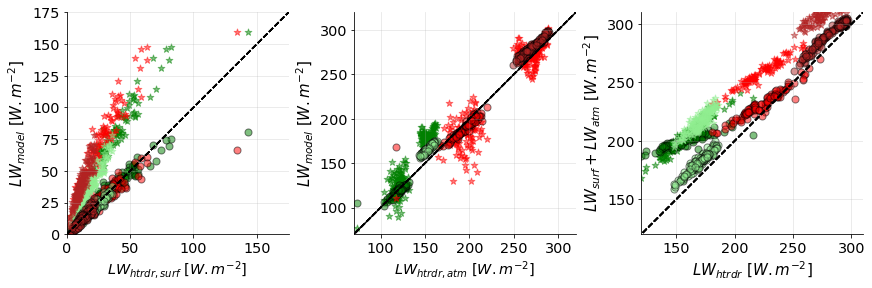

In [20]:
fig,axs = plt.subplots(nrows = 1, ncols = 3, figsize = (12,4), layout = 'constrained')

correlation_htrdr_model_surf(
        ax = axs[0],
        alpha = 0.5,
        epsilon_atm = 1,
        epsilon_surf = 0.98,
        atm_ = ["SMLWATM","SMLSATM"],
        ds_ecrins = ds_ecrins,
        ds_chartreuse = ds_chartreuse)

correlation_htrdr_model_atm(
        ax = axs[1],
        alpha = 0.5,
        epsilon_atm = 1,
        epsilon_surf = 0.98,
        atm_ = ["SMLWATM","SMLSATM"])

correlation_htrdr_model_total(
        ax = axs[2],
        alpha = 0.5,
        epsilon_atm = 1,
        epsilon_surf = 0.98,
        atm_ = ["SMLSATM","SMLWATM"],
        ds_chartreuse = ds_chartreuse,
        ds_ecrins = ds_ecrins)

for ax in axs : 
    ax.grid(True, alpha=0.3)

#plt.savefig("/home/barroisl/Transect_MC_auto/Output/chartreuse_250_100_atms/all_composante_model.png")

# Histogramme spectral

In [141]:
def plot_lambda_filter_new_chartreuse(
    ax,
    ncam : int):
    
    path_dir = "/home/barroisl/Transect_MC_auto/Data/chartreuse_250_100_atms/"
        
    for i,atm in enumerate(atms[::-1]):
        
        if os.path.isdir(path_dir + atm):
        
            bins = np.linspace(4,60,40)

            data = np.loadtxt(path_dir + atm +f'/{ncam}/{ncam}_50_15_15.txt')
            pos_camera = np.loadtxt(path_dir + atm +f'/{ncam}/{ncam}_camera_tgt.txt')[:3]
            mc_set = MC_Set(data, pos_camera)

            lambdas_surf = np.array(mc_set.distrib_lambda(True))*1e-3
            ax.hist(lambdas_surf, bins = bins, histtype = 'bar',linestyle = 'solid', \
                    color = dict_atm[atm][1],label = dict_atm[atm][4], alpha = 0.25)
            
            T_obs,T_ref = 275, 275
            F_CN = sigma*T_obs**4
            F_tot = ((sigma*T_ref**4)/mc_set.Nbre_photon)*np.sum(1e-6*Planck_law(wavelength=lambdas_surf*1e-6,temperature=T_obs)/\
                           (1e-6*Planck_law(wavelength=lambdas_surf*1e-6,temperature=T_ref)))
            emissivity_eff = F_tot/F_CN
            
            wl = np.linspace(0,65,1000)
            ax.plot(wl,11250*np.pi*emissivity_eff*1e-6*Planck_law(wavelength=wl*1e-6,temperature=T_obs)/(sigma*T_obs**4),\
                       label = dict_atm[atm][4] +" $(1-SVF)\epsilon_s \sigma T_{s}^{4}$" , color = dict_atm[atm][1])
        
    #ax.tick_params(axis="both", labelsize=20)
    ax.set_ylabel('Count')
    ax.set_xlabel('$\lambda$ $[\mu m]$')
    ax.spines[['right', 'top']].set_visible(False)
    ax.grid(True, alpha = 0.3)
    #ax.legend(ncol = 4)
    
def hist_temp(
        ax,
        ds_chartreuse,
        ncam : int):
    
    path_dir = "/home/barroisl/Transect_MC_auto/Data/chartreuse_250_100_atms/"
    cam_tgt = np.loadtxt("/home/barroisl/Transect_MC_auto/camera_tgt/polygon_chartreuse_250_100.txt")
    
    for atm in atms[::-1]:
        
        if os.path.isdir(path_dir + atm):
            
            #if atm == 'SMLSATM':
        
            bins = np.linspace(270,290,30)

            data = np.loadtxt(path_dir + atm +f'/{ncam}/{ncam}_50_15_15.txt')
            Ts = np.zeros(data[data[:,1]==0,3].size)

            for j in range(data[data[:,1]==0,3].size):
                Ts[j] = ds_chartreuse.ts.interp(x = data[data[:,1]==0][j,3], y = data[data[:,1]==0][j,4], method="nearest").values
                #Ts[i] = ds_chartreuse.ts.interp(x = data[data[:,1]==0][i,3], y = data[data[:,1]==0][i,3]).values

            ax.hist(Ts, bins = bins, histtype = 'bar',linestyle = 'solid', \
                    color = dict_atm[atm][1], alpha = 0.25)

        T_pyr = ds_chartreuse.ts.interp(x = cam_tgt[ncam,0], y = cam_tgt[ncam,1]).values
        ax.vlines(T_pyr,0,60, color = 'k')

    ax.annotate("$T_{pyr}$", xy = (T_pyr-0.2,65), fontsize = 20)
    ax.grid(True, alpha = 0.3)
    ax.set_ylabel('Count')
    ax.set_xlabel('$T_{s}$ $[K]$')
    ax.spines[['right', 'top']].set_visible(False)

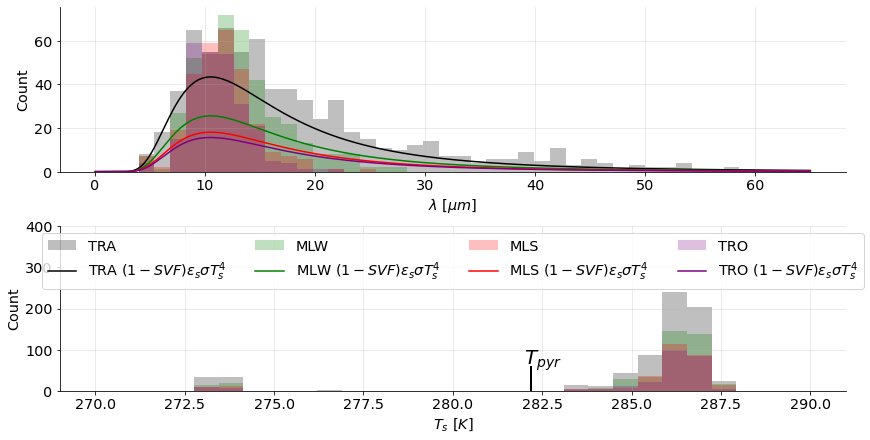

In [146]:
fig, axs = plt.subplots(nrows = 2, ncols = 1, figsize = (12,6), layout = 'constrained')

ncam = 17
ds_chartreuse = xr.open_dataset("/home/barroisl/Transect_MC_auto/topographie/chartreuse_thomas_topo_params.nc")

plot_lambda_filter_new_chartreuse(
    ax = axs[0],
    ncam = ncam)

hist_temp(
        ax = axs[1],
        ds_chartreuse = ds_chartreuse,
        ncam = ncam)

handles, labels = [], []
for a in fig.axes:
    h, l = a.get_legend_handles_labels()
    handles += h
    labels += l
    
axs[1].set_ylim((0,400))
axs[1].legend(handles, labels,ncol = 4, loc = 'upper center')

plt.savefig("/home/barroisl/git/improving-irradiance-over-complex-terrain/Figures/lambda_filter_weights.png")